# Ancient DNA Population Analysis

This project explores ancient DNA data using data science and machine learning techniques. The analysis focuses on archaeological context, geographic distribution, chronology, population structure, and later PCA and clustering methods.

## Methodological Notes

The genotype data used in the selected ancient samples were effectively represented using pseudohaploid allele calls.

Physical SNP thinning at 50 kb intervals was used as a lightweight approximation for reducing highly local marker redundancy. This should not be interpreted as formal linkage-disequilibrium pruning.

Archaeological periods were derived from broad patterns in source `Group ID` labels and are intended as analytical context rather than precise cultural classifications.

PCA and K-Means identify statistical patterns in genetic variation. They do not independently demonstrate ancestry proportions, migration events, population replacement, or causal historical processes.

## Key Conclusion

The analysis identifies a strong broad-scale genetic distinction between Neolithic individuals and later ancient populations from Britain and Ireland.

After the Neolithic, genetic structure becomes substantially more overlapping and continuous. Exploratory clustering did not provide robust evidence for multiple discrete post-Neolithic populations after site-specific outliers were investigated.

The project also demonstrates the importance of quality control, metadata interpretation, outlier investigation, and sensitivity analysis when applying data-science methods to ancient DNA.

## Tools

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.

## Author

**Amir Mehdi Memari**  
MSc Data Science & Machine Learning  
Sultan Qaboos University

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load the Ancient DNA Metadata

The metadata file contains archaeological, geographic, and genetic information for ancient and reference individuals. We first load the dataset and check its overall size.

In [12]:
from pathlib import Path
import os

current_folder = Path.cwd()

if (current_folder / "data" / "raw").exists():
    project_root = current_folder
elif (current_folder.parent / "data" / "raw").exists():
    project_root = current_folder.parent
else:
    raise FileNotFoundError("Could not locate the project root.")

os.chdir(project_root)

print("Working directory:")
print(Path.cwd())

Working directory:
C:\Users\Amir\Desktop\Github Projects\ancient-dna-population-analysis


In [13]:
metadata_path = "data/raw/COMMIOS_aadr_HO_v62.anno.gz"

df = pd.read_csv(
    metadata_path,
    sep="\t",
    compression="gzip"
)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

Dataset loaded successfully
Dataset shape: (6872, 42)


## 3. Inspect the Dataset

Before starting the analysis, we inspect the first few rows of the dataset to understand how the archaeological and genetic information is organized.

In [14]:
df.head()

,"Genetic ID (suffixes: """".DG"""" is a high coverage shotgun genome with diploid genotype calls, """".AG"""" is shotgun data with each position in the genome represented by a randomly chosen sequence, """".HO"""" is Affymetrix Human Origins genotype data)",Master ID,Skeletal code,Skeletal element,"Year data from this individual was first published [for a present-day individuals we give the data of the data reported here; missing GreenScience 2010 (Vi33.15, Vi33.26), Olalde2018 (I2657), RasmussenNature2010 (Australian)]",Publication abbreviation,doi for publication of this representation of the data,Link to the most permanent repository hosting these data,"Method for Determining Date; unless otherwise specified, calibrations use 95.4% intervals from OxCal v4.4.2 Bronk Ramsey (2009); r5; Atmospheric data from Reimer et al (2020)","Date mean in BP in years before 1950 CE [OxCal mu for a direct radiocarbon date, and average of range for a contextual date]","Date standard deviation in BP [OxCal sigma for a direct radiocarbon date, and standard deviation of the uniform distribution between the two bounds for a contextual date]","Full Date One of two formats. (Format 1) 95.4% CI calibrated radiocarbon age (Conventional Radiocarbon Age BP, Lab number) e.g. 2624-2350 calBCE (3990±40 BP, Ua-35016). (Format 2) Archaeological context range, e.g. 2500-1700 BCE","Age at death, Morphological sex from physical anthropology",Group ID,Locality,Political Entity,Lat.,Long.,Pulldown Strategy,Suffices (indicating data types used for sources which can be a subset of that in bam),Data type,No. Libraries,SNPs hit on autosomal targets (Computed using easystats on 1240k snpset),SNPs hit on autosomal targets (Computed using easystats on HO snpset),Molecular Sex,Sum total of ROH segments >4 cM,Sum total of ROH segments >20cM,Y haplogroup in terminal mutation notation automatically called based on Yfull with the software described in Lazaridis et al. Science 2022,Y haplogroup in ISOGG v15.73 notation automatically called based on Yfull with the software described in Lazaridis et al. Science 2022,Y haplogroup manually called if different from automatic,mtDNA coverage (merged data),mtDNA haplogroup if >2x or published,mtDNA match to consensus if >2x (merged data),Damage rate in first nucleotide on sequences overlapping 1240k targets (merged data),Sex ratio [Y/(Y+X) counts] (merged data),ANGSD MOM 95% CI truncated at 0 (only if male and >=200 SNPs),hapConX 95% CI truncated at 0 (only if male and >=2000 SNPs covered on X chromosome),"Library type (minus=no.damage.correction, half=damage.retained.at.last.position, plus=damage.fully.corrected, ds=double.stranded.library.preparation, ss=single.stranded.library.preparation)",Libraries,endogenous by library (computed on shotgun data),ASSESSMENT,ASSESSMENT WARNING
0,I0001.AG,Loschbour,Loschbour2,tooth,2014,MathiesonNature2018,doi:10.1038/nature25778,ENA:PRJEB22652,Direct: IntCal20,8025,64,"6221-5986 calBCE (7205±50 BP, OxA-7738)",34-47 yrs,Luxembourg_Mesolithic.AG,Loschbour (Echternach),Luxembourg,49.81,6.4,Native Pulldown on 3.2M snpset,AG,390K,..,463455,366175,M,121.049706,0,I-M423,I2a1a2,..,..,U5b1a,..,..,..,..,"[0.005,0.012]",..,..,..,PASS,"hapConX=[0.005,0.012]"
1,CL146.AG,CL146,CL146,petrous,2018,AmorimNatureCommunications2018,doi:10.1038/s41467-018-06024-4,NCBI sequence read archive (SRA) database unde...,Context: Archaeological,1345,14,580-630 CE,..,Italy_North_EarlyMedieval_Langobards_1.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,Native Pulldown on 3.2M snpset,AG,1240k,..,849289,447138,M,5.933404,0,R-S17624,R1b1a1b1a1a,..,12.56,T2b3,..,0.1042,..,"[0,0.006]","[0.002,0.005]",ds.half,..,0.35136,PASS,..
2,CL23.AG,CL23,CL23,petrous,2018,AmorimNatureCommunications2018,doi:10.1038/s41467-018-06024-4,NCBI sequence read archive (SRA) database unde...,Context: Archaeological,1345,14,580-630 CE,..,Italy_North_EarlyMedieval_Langobards_2.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,Native Pulldown on 

## 4. Inspect the Dataset Columns

The dataset contains many archaeological, geographic, genetic, and laboratory-related variables. We list all column names so we can identify the fields most useful for our population analysis.

In [15]:
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. Genetic ID (suffixes: "".DG"" is a high coverage shotgun genome with diploid genotype calls, "".AG"" is shotgun data with each position in the genome represented by a randomly chosen sequence, "".HO"" is Affymetrix Human Origins genotype data)
2. Master ID
3. Skeletal code
4. Skeletal element
5. Year data from this individual was first published [for a present-day individuals we give the data of the data reported here; missing GreenScience 2010 (Vi33.15, Vi33.26), Olalde2018 (I2657), RasmussenNature2010 (Australian)]
6. Publication abbreviation
7. doi for publication of this representation of the data
8. Link to the most permanent repository hosting these data
9. Method for Determining Date; unless otherwise specified, calibrations use 95.4% intervals from OxCal v4.4.2 Bronk Ramsey (2009); r5; Atmospheric data from Reimer et al (2020)
10. Date mean in BP in years before 1950 CE [OxCal mu for a direct radiocarbon date, and average of range for a contextual date]
11. Date standard dev

## 5. Select Relevant Archaeological and Genetic Variables

The original dataset contains 42 variables, including publication, laboratory, sequencing, archaeological, geographic, and genetic information. For the main analysis, we keep the variables most useful for chronology, geography, population grouping, genetic coverage, biological sex, ancestry, and sample quality.

In [16]:
selected_columns = [
    "Genetic ID (suffixes: \"\".DG\"\" is a high coverage shotgun genome with diploid genotype calls, \"\".AG\"\" is shotgun data with each position in the genome represented by a randomly chosen sequence, \"\".HO\"\" is Affymetrix Human Origins genotype data)",
    "Master ID",
    "Skeletal element",
    "Date mean in BP in years before 1950 CE [OxCal mu for a direct radiocarbon date, and average of range for a contextual date]",
    "Date standard deviation in BP [OxCal sigma for a direct radiocarbon date, and standard deviation of the uniform distribution between the two bounds for a contextual date]",
    "Full Date One of two formats. (Format 1) 95.4% CI calibrated radiocarbon age (Conventional Radiocarbon Age BP, Lab number) e.g. 2624-2350 calBCE (3990±40 BP, Ua-35016). (Format 2) Archaeological context range, e.g. 2500-1700 BCE",
    "Group ID",
    "Locality",
    "Political Entity",
    "Lat.",
    "Long.",
    "SNPs hit on autosomal targets (Computed using easystats on HO snpset)",
    "Molecular Sex",
    "mtDNA haplogroup if >2x or published",
    "ASSESSMENT"
]

metadata = df[selected_columns].copy()

print("Selected metadata shape:", metadata.shape)
metadata.head()

Selected metadata shape: (6872, 15)


,"Genetic ID (suffixes: """".DG"""" is a high coverage shotgun genome with diploid genotype calls, """".AG"""" is shotgun data with each position in the genome represented by a randomly chosen sequence, """".HO"""" is Affymetrix Human Origins genotype data)",Master ID,Skeletal element,"Date mean in BP in years before 1950 CE [OxCal mu for a direct radiocarbon date, and average of range for a contextual date]","Date standard deviation in BP [OxCal sigma for a direct radiocarbon date, and standard deviation of the uniform distribution between the two bounds for a contextual date]","Full Date One of two formats. (Format 1) 95.4% CI calibrated radiocarbon age (Conventional Radiocarbon Age BP, Lab number) e.g. 2624-2350 calBCE (3990±40 BP, Ua-35016). (Format 2) Archaeological context range, e.g. 2500-1700 BCE",Group ID,Locality,Political Entity,Lat.,Long.,SNPs hit on autosomal targets (Computed using easystats on HO snpset),Molecular Sex,mtDNA haplogroup if >2x or published,ASSESSMENT
0,I0001.AG,Loschbour,tooth,8025,64,"6221-5986 calBCE (7205±50 BP, OxA-7738)",Luxembourg_Mesolithic.AG,Loschbour (Echternach),Luxembourg,49.81,6.4,366175,M,U5b1a,PASS
1,CL146.AG,CL146,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_1.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,447138,M,T2b3,PASS
2,CL23.AG,CL23,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_2.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,455929,M,H,PASS
3,CL25.AG,CL25,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_3.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,369793,F,H,PASS
4,CL30.AG,CL30,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_3.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,443632,M,I1b,PASS


## 6. Simplify Column Names

Several column names in the original dataset are very long because they include detailed methodological descriptions. To make the analysis easier to read and maintain, we rename the selected variables using shorter and clearer names.

In [17]:
metadata = metadata.rename(
    columns={
        metadata.columns[0]: "genetic_id",
        "Master ID": "sample_id",
        "Skeletal element": "skeletal_element",
        "Date mean in BP in years before 1950 CE [OxCal mu for a direct radiocarbon date, and average of range for a contextual date]": "date_bp",
        "Date standard deviation in BP [OxCal sigma for a direct radiocarbon date, and standard deviation of the uniform distribution between the two bounds for a contextual date]": "date_sd",
        "Full Date One of two formats. (Format 1) 95.4% CI calibrated radiocarbon age (Conventional Radiocarbon Age BP, Lab number) e.g. 2624-2350 calBCE (3990±40 BP, Ua-35016). (Format 2) Archaeological context range, e.g. 2500-1700 BCE": "full_date",
        "Group ID": "group_id",
        "Locality": "locality",
        "Political Entity": "country",
        "Lat.": "latitude",
        "Long.": "longitude",
        "SNPs hit on autosomal targets (Computed using easystats on HO snpset)": "ho_snps",
        "Molecular Sex": "molecular_sex",
        "mtDNA haplogroup if >2x or published": "mtdna_haplogroup",
        "ASSESSMENT": "assessment"
    }
)

print(metadata.columns.tolist())
metadata.head()

['genetic_id', 'sample_id', 'skeletal_element', 'date_bp', 'date_sd', 'full_date', 'group_id', 'locality', 'country', 'latitude', 'longitude', 'ho_snps', 'molecular_sex', 'mtdna_haplogroup', 'assessment']


,genetic_id,sample_id,skeletal_element,date_bp,date_sd,full_date,group_id,locality,country,latitude,longitude,ho_snps,molecular_sex,mtdna_haplogroup,assessment
0,I0001.AG,Loschbour,tooth,8025,64,"6221-5986 calBCE (7205±50 BP, OxA-7738)",Luxembourg_Mesolithic.AG,Loschbour (Echternach),Luxembourg,49.81,6.4,366175,M,U5b1a,PASS
1,CL146.AG,CL146,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_1.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,447138,M,T2b3,PASS
2,CL23.AG,CL23,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_2.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,455929,M,H,PASS
3,CL25.AG,CL25,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_3.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,369793,F,H,PASS
4,CL30.AG,CL30,petrous,1345,14,580-630 CE,Italy_North_EarlyMedieval_Langobards_3.AG,"Collegno (Piedmont, Turin)",Italy,45.0792,7.5783,443632,M,I1b,PASS


## 7. Explore Geographic Representation

To understand the geographic composition of the dataset, we count how many individuals are associated with each country. This helps identify regions with enough samples for focused population analysis.

In [18]:
metadata["country"].value_counts().head(20)

country
United Kingdom    1111
Hungary            880
Russia             640
Spain              500
Italy              351
Germany            335
France             301
Turkey             260
Croatia            206
Denmark            168
Sweden             166
Israel             146
Poland             141
Armenia            132
Iran               127
Serbia             125
Ukraine            107
Greece             104
Ireland            102
Bulgaria            99
Name: count, dtype: int64

## 8. Filter Samples from Britain and Ireland

The main analysis focuses on samples associated with the United Kingdom and Ireland. This creates a geographically focused subset that can later be examined across archaeological periods and genetic population groups.

In [19]:
britain_ireland = metadata[
    metadata["country"].isin(["United Kingdom", "Ireland"])
].copy()

print("Britain & Ireland samples:", britain_ireland.shape[0])

print(
    "Samples with archaeological dates:",
    britain_ireland["date_bp"].notna().sum()
)

print(
    "Samples without archaeological dates:",
    britain_ireland["date_bp"].isna().sum()
)

Britain & Ireland samples: 1213
Samples with archaeological dates: 1213
Samples without archaeological dates: 0


## 9. Inspect the Chronological Range

All Britain and Ireland samples contain a value in the dating field. We inspect the minimum and maximum dates and view the most recent samples to confirm the chronological range before defining archaeological periods.

In [20]:
print("Minimum date (BP):", britain_ireland["date_bp"].min())
print("Maximum date (BP):", britain_ireland["date_bp"].max())

britain_ireland[
    ["sample_id", "locality", "country", "date_bp", "full_date", "group_id"]
].sort_values("date_bp").head(15)

Minimum date (BP): 0
Maximum date (BP): 10546


,sample_id,locality,country,date_bp,full_date,group_id
5793,HG00252,Cornwall (England),United Kingdom,0,present,GBR.DG
5792,HG00251,Cornwall (England),United Kingdom,0,present,GBR.DG
5758,HG00145,Kent (England),United Kingdom,0,present,GBR.DG
5757,HG00143,Kent (England),United Kingdom,0,present,GBR.DG
5761,HG00108,Orkney (Scotland),United Kingdom,0,present,GBR.DG
5767,HG00120,Orkney (Scotland),United Kingdom,0,present,GBR.DG
5764,HG02215,Kent (England),United Kingdom,0,present,GBR.DG
5762,HG00109,Orkney (Scotland),United Kingdom,0,present,GBR.DG
5768,HG00121,Orkney (Scotland),United Kingdom,0,present,GBR.DG
5779,HG01334,Kent (England),United Kingdom,0,present,GBR.DG


## 10. Separate Archaeological and Present-Day Samples

The chronological inspection shows that present-day individuals are represented with a date of 0 BP and labelled as "present". We separate these modern reference individuals from the archaeological samples so that ancient population patterns can be analysed independently while retaining modern samples for later comparison.

In [21]:
ancient_samples = britain_ireland[
    britain_ireland["date_bp"] > 0
].copy()

modern_samples = britain_ireland[
    britain_ireland["date_bp"] == 0
].copy()

print("Archaeological samples:", ancient_samples.shape[0])
print("Present-day reference samples:", modern_samples.shape[0])
print("Total:", ancient_samples.shape[0] + modern_samples.shape[0])

Archaeological samples: 1108
Present-day reference samples: 105
Total: 1213


## 11. Examine the Age Range of the Archaeological Samples

Before dividing the archaeological individuals into historical periods, we inspect their chronological range. This helps us understand how far back the dataset extends and provides a basis for creating meaningful time-period categories.

In [22]:
print("Oldest sample (BP):", ancient_samples["date_bp"].max())
print("Most recent archaeological sample (BP):", ancient_samples["date_bp"].min())

ancient_samples[
    ["sample_id", "locality", "country", "date_bp", "full_date", "group_id"]
].sort_values("date_bp", ascending=False).head(10)

Oldest sample (BP): 10546
Most recent archaeological sample (BP): 768


,sample_id,locality,country,date_bp,full_date,group_id
796,I6745,"Aveline's Hole (England, Somerset, Burrington ...",United Kingdom,10546,"8751-8433 calBCE (9340±50 BP, OxA-34338)",England_Mesolithic.AG
795,I6744,"Aveline's Hole (England, Somerset, Burrington ...",United Kingdom,10393,"8606-8300 calBCE (9230±50 BP, OxA-34339)",England_Mesolithic_o1.AG
1509,I6767,"Gough's Cave (England, Somerset, Cheddar)",United Kingdom,10280,"8615-7966 calBCE (9100±100 BP, OxA-814)",England_Mesolithic.AG.SG
812,I6767,"Gough's Cave (England, Somerset, Cheddar)",United Kingdom,10280,"8615-7966 calBCE (9100±100 BP, OxA-814)",England_Mesolithic.AG
5715,I6767,"Gough's Cave (England, Somerset, Cheddar)",United Kingdom,10280,"8615-7966 calBCE (9100±100 BP, OxA-814)",England_Mesolithic.AG
803,I6754,"Ogof-Yr-Ychen (Wales, Pembrokeshire, Caldey Is...",United Kingdom,9580,"7739-7536 calBCE (8597±54 BP, UBA-32282)",Wales_Mesolithic.AG
1489,I3025,"Kent's Cavern (England, Devon, Torquay)",United Kingdom,9257,"7476-7085 calBCE (8270±45 BP, OxA-23812)",England_Mesolithic.AG.SG
1483,I3025,"Kent's Cavern (England, Devon, Torquay)",United Kingdom,9257,"7476-7085 calBCE (8270±45 BP, OxA-23812)",England_Mesolithic.AG.SG
153,I3025,"Kent's Cavern (England, Devon, Torquay)",United Kingdom,9257,"7476-7085 calBCE (8270±45 BP, OxA-23812)",England_Mesolithic.AG
1567,KGH6,Killuragh (County Limerick),Ireland,6658,"4797-4602 calBCE (5844±35 BP, UBA-40235)",Ireland_Mesolithic.SG


## 12. Check for Duplicate Individuals

Some archaeological individuals may appear multiple times because different genetic datasets or sequencing representations are available for the same person. We check the number of unique individuals before continuing so that repeated records do not bias later analyses.

In [23]:
print("Total archaeological records:", ancient_samples.shape[0])
print("Unique individuals:", ancient_samples["sample_id"].nunique())

duplicate_count = ancient_samples["sample_id"].duplicated().sum()

print("Duplicate records:", duplicate_count)

Total archaeological records: 1108
Unique individuals: 1031
Duplicate records: 77


## 13. Inspect Duplicate Sample Representations

Repeated sample IDs may represent the same archaeological individual processed using different genetic data types or sequencing approaches. We inspect these duplicate records before deciding which representation should be retained for genetic analysis.

In [24]:
duplicate_samples = ancient_samples[
    ancient_samples["sample_id"].duplicated(keep=False)
].copy()

duplicate_samples[
    [
        "sample_id",
        "genetic_id",
        "group_id",
        "date_bp",
        "ho_snps",
        "assessment"
    ]
].sort_values(["sample_id", "ho_snps"], ascending=[True, False]).head(30)

,sample_id,genetic_id,group_id,date_bp,ho_snps,assessment
3222,I0157,I0157.SG,England_EarlyMedieval_Saxon.SG,1227,562921,PASS
941,I0157,I0157.AG,England_EarlyMedieval_Saxon.AG,1227,538642,PASS
3223,I0159,I0159.SG,England_EarlyMedieval_Saxon.SG,1234,552379,PASS
942,I0159,I0159.AG,England_EarlyMedieval_Saxon.AG,1234,520629,PASS
943,I0161,I0161.AG,England_EarlyMedieval_Saxon.AG,1157,413517,PASS
3225,I0161,I0161.SG,England_EarlyMedieval_Saxon.SG,1157,327498,PASS
3226,I0769,I0769.SG,England_EarlyMedieval_Saxon.SG,1449,500476,PASS
974,I0769,I0769.AG,England_EarlyMedieval_Saxon.AG,1449,493857,PASS
975,I0773,I0773.AG,England_EarlyMedieval_Saxon.AG,1479,488679,PASS
3227,I0773,I0773.SG,England_EarlyMedieval_Saxon.SG,1479,452588,PASS


## 14. Check Sample Quality Assessments

Ancient DNA samples can differ in sequencing quality and reliability. Before removing duplicate representations, we inspect the quality-assessment labels so that sample quality can be considered alongside SNP coverage when selecting the best record for each individual.

In [25]:
ancient_samples["assessment"].value_counts(dropna=False)

assessment
PASS            1001
QUESTIONABLE      64
CRITICAL          41
MERGE_PASS         2
Name: count, dtype: int64

## 15. Retain Samples with Acceptable Quality Assessments

For the main analysis, we retain records labelled `PASS` or `MERGE_PASS`. Samples labelled `QUESTIONABLE` or `CRITICAL` are kept out of the primary analysis so that lower-confidence records do not influence later PCA and clustering results.

In [26]:
quality_samples = ancient_samples[
    ancient_samples["assessment"].isin(["PASS", "MERGE_PASS"])
].copy()

print("Records before quality filtering:", ancient_samples.shape[0])
print("Records after quality filtering:", quality_samples.shape[0])
print("Unique individuals after filtering:", quality_samples["sample_id"].nunique())
print("Excluded records:", ancient_samples.shape[0] - quality_samples.shape[0])

Records before quality filtering: 1108
Records after quality filtering: 1003
Unique individuals after filtering: 942
Excluded records: 105


## 16. Select the Best Genetic Representation per Individual

Some individuals still have more than one high-quality genetic record. To avoid counting the same person multiple times, we retain the representation with the highest number of Human Origins SNPs for each individual.

In [27]:
clean_samples = (
    quality_samples
    .sort_values("ho_snps", ascending=False)
    .drop_duplicates(subset="sample_id", keep="first")
    .copy()
)

print("Records before duplicate removal:", quality_samples.shape[0])
print("Records after duplicate removal:", clean_samples.shape[0])
print("Unique individuals:", clean_samples["sample_id"].nunique())
print("Duplicates remaining:", clean_samples["sample_id"].duplicated().sum())

Records before duplicate removal: 1003
Records after duplicate removal: 942
Unique individuals: 942
Duplicates remaining: 0


## 17. Examine the Chronological Distribution

After quality filtering and duplicate removal, we examine the age distribution of the remaining archaeological individuals. This helps us decide how to divide the samples into meaningful chronological periods for later analysis.

In [28]:
clean_samples["date_bp"].describe()

count      942.000000
mean      2740.755839
std       1562.765610
min        768.000000
25%       1450.000000
50%       2225.500000
75%       3805.250000
max      10546.000000
Name: date_bp, dtype: float64

## 18. Visualize the Chronological Distribution

A histogram is used to examine how the 942 archaeological individuals are distributed through time. Dates are expressed as years before present (BP), where larger values represent older samples.

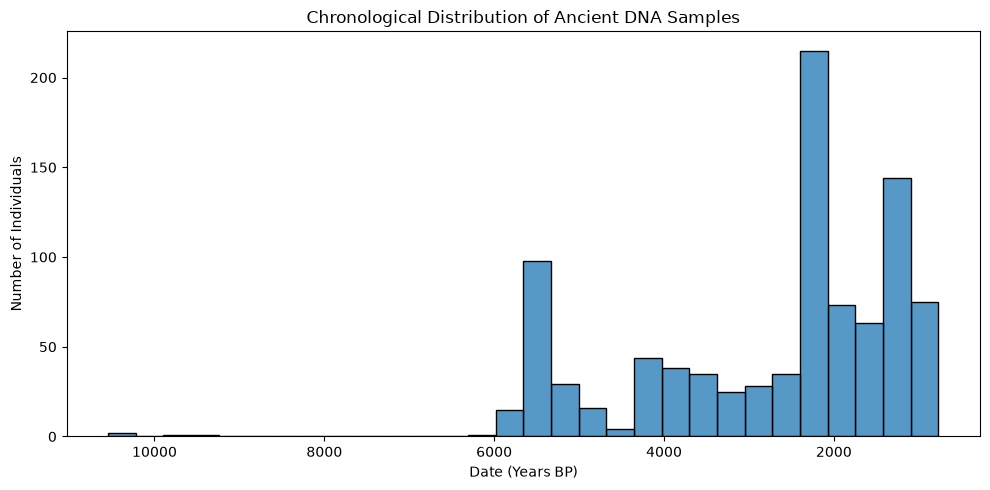

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=clean_samples,
    x="date_bp",
    bins=30
)

plt.title("Chronological Distribution of Ancient DNA Samples")
plt.xlabel("Date (Years BP)")
plt.ylabel("Number of Individuals")

plt.gca().invert_xaxis()

plt.tight_layout()

plt.savefig(
    "images/plots/chronological_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 19. Inspect Archaeological Population Groups

The dataset already contains population and archaeological group labels assigned to the samples. We inspect the most common groups before creating broader chronological categories, helping us preserve the archaeological context provided by the original dataset.

In [30]:
clean_samples["group_id"].value_counts().head(30)

group_id
England_MIA.AG                                            86
England_MIA_LIA.AG                                        65
England_EarlyMedieval_Saxon.AG                            56
England_Saxon.AG                                          44
England_Saxon.SG                                          36
Ireland_Kilteasheen_EarlyMedieval_AngloSaxon_Norman.AG    34
England_EarlyMedieval.AG                                  32
England_EIA.AG                                            31
England_C_EBA.AG                                          31
Scotland_N.AG                                             30
England_EastYorkshire_MIA_LIA.AG                          28
England_Viking.SG                                         26
Ireland_MN.SG                                             25
England_LIA.AG                                            22
England_MBA.AG                                            22
England_BellBeaker.AG                                     18
Scotland_Orkney

## 20. Convert BP Dates to Approximate Calendar Years

The dataset expresses dates as years before present (BP), where "present" is defined as 1950 CE. To make the chronology easier to interpret, the BP values are converted into approximate calendar years. Negative values represent BCE, while positive values represent CE.

In [31]:
clean_samples["calendar_year"] = 1950 - clean_samples["date_bp"]

print(
    "Earliest approximate calendar year:",
    clean_samples["calendar_year"].min()
)

print(
    "Latest approximate calendar year:",
    clean_samples["calendar_year"].max()
)

clean_samples[
    ["sample_id", "date_bp", "calendar_year", "full_date", "group_id"]
].sort_values("date_bp", ascending=False).head(10)

Earliest approximate calendar year: -8596
Latest approximate calendar year: 1182


,sample_id,date_bp,calendar_year,full_date,group_id
796,I6745,10546,-8596,"8751-8433 calBCE (9340±50 BP, OxA-34338)",England_Mesolithic.AG
1509,I6767,10280,-8330,"8615-7966 calBCE (9100±100 BP, OxA-814)",England_Mesolithic.AG.SG
803,I6754,9580,-7630,"7739-7536 calBCE (8597±54 BP, UBA-32282)",Wales_Mesolithic.AG
1489,I3025,9257,-7307,"7476-7085 calBCE (8270±45 BP, OxA-23812)",England_Mesolithic.AG.SG
1494,I3065,6290,-4340,"4444-4255 calBCE (5492±36 BP, SUERC-69249)",Scotland_Mesolithic.AG.SG
799,I6748,5813,-3863,"3956-3769 calBCE (5052±32 BP, OxA-19914)",England_N_o.AG
564,I2658,5800,-3850,4000-3700 BCE,Scotland_N_1d.rel.or_dup.I2657.AG
1504,I6760,5781,-3831,"3946-3710 calBCE (5023±34 BP, OxA-17173)",England_N.AG.SG
1589,PN10_PN113,5746,-3796,"3945-3656 calBCE (5004±31 BP, OxA-25950)",Ireland_EN.SG
1584,PN04,5742,-3792,"3946-3653 calBCE (4999±48 BP, UBA-38312)",Ireland_EN.SG


## 21. Create Broad Archaeological Periods

To make later comparisons easier, the detailed population labels are grouped into broader archaeological periods. These categories are derived primarily from the period information already encoded in the dataset's `group_id` values rather than assigning cultural identities from dates alone.

In [32]:
def get_period(group):
    group = str(group)

    if "Mesolithic" in group:
        return "Mesolithic"

    elif any(x in group for x in ["_EN", "_MN", "_LN", "_N_", "_N.", "Megalithic"]):
        return "Neolithic"

    elif any(x in group for x in ["EBA", "MBA", "LBA", "BellBeaker"]):
        return "Bronze Age"

    elif any(x in group for x in ["EIA", "MIA", "LIA", "_IA"]):
        return "Iron Age"

    elif "Roman" in group:
        return "Roman"

    elif any(x in group for x in ["EarlyMedieval", "Saxon", "Viking"]):
        return "Early Medieval"

    elif any(x in group for x in ["Medieval", "Norman"]):
        return "Medieval"

    else:
        return "Unclassified"


clean_samples["period"] = clean_samples["group_id"].apply(get_period)

clean_samples["period"].value_counts()

period
Iron Age          324
Early Medieval    269
Bronze Age        170
Neolithic         162
Unclassified        6
Mesolithic          5
Medieval            5
Roman               1
Name: count, dtype: int64

## 22. Validate Archaeological Period Classification

Before using the archaeological periods in later analysis, we inspect samples that were not classified and groups containing Roman-period labels. This helps identify any classification rules that need correction before continuing.

In [33]:
print("Unclassified groups:")
print(
    clean_samples.loc[
        clean_samples["period"] == "Unclassified",
        "group_id"
    ].value_counts()
)

print("\nGroups containing 'Roman':")
print(
    clean_samples.loc[
        clean_samples["group_id"].str.contains("Roman", case=False, na=False),
        ["group_id", "period"]
    ].value_counts()
)

Unclassified groups:
group_id
England_Scorton_Anglian.AG          5
England_EastYorkshire_Anglian.AG    1
Name: count, dtype: int64

Groups containing 'Roman':
group_id                         period  
England_IA_Roman.SG              Iron Age    6
England_IA_Roman_oMiddleEast.SG  Iron Age    1
England_IA_ERoman.SG             Iron Age    1
England_Roman.AG                 Roman       1
Name: count, dtype: int64


## 23. Refine the Archaeological Period Classification

The initial classification placed some Roman-labelled groups within the Iron Age because the `IA` rule was checked first. We refine the classification by prioritizing explicit Roman labels and including Anglian groups within the broader Early Medieval category.

In [34]:
def get_period(group):
    group = str(group)

    if "Mesolithic" in group:
        return "Mesolithic"

    elif any(x in group for x in ["_EN", "_MN", "_LN", "_N_", "_N.", "Megalithic"]):
        return "Neolithic"

    elif any(x in group for x in ["EBA", "MBA", "LBA", "BellBeaker"]):
        return "Bronze Age"

    elif "Roman" in group:
        return "Roman"

    elif any(x in group for x in ["EIA", "MIA", "LIA", "_IA"]):
        return "Iron Age"

    elif any(x in group for x in ["EarlyMedieval", "Saxon", "Viking", "Anglian"]):
        return "Early Medieval"

    elif any(x in group for x in ["Medieval", "Norman"]):
        return "Medieval"

    else:
        return "Unclassified"


clean_samples["period"] = clean_samples["group_id"].apply(get_period)

clean_samples["period"].value_counts()

period
Iron Age          316
Early Medieval    275
Bronze Age        170
Neolithic         162
Roman               9
Mesolithic          5
Medieval            5
Name: count, dtype: int64

## 24. Validate the Chronology of Archaeological Periods

To check the consistency of the period classification, we summarize the number of individuals and the date range within each archaeological period. This helps identify possible classification errors before the period labels are used in later analyses.

In [35]:
period_summary = (
    clean_samples
    .groupby("period")["date_bp"]
    .agg(["count", "min", "median", "max"])
    .sort_values("median", ascending=False)
)

period_summary

,count,min,median,max
period,,,,
Mesolithic,5,6290,9580.0,10546
Neolithic,162,4433,5474.5,5813
Bronze Age,170,2789,3628.0,4333
Iron Age,316,1381,2201.5,2644
Roman,9,1750,1750.0,1981
Early Medieval,275,856,1200.0,1589
Medieval,5,768,768.0,784


## 25. Inspect Chronological Outliers in the Iron Age Group

The Iron Age category contains a few samples with relatively recent dates. These records are inspected to determine whether their original population labels represent transitional, mixed, or unusually broad archaeological classifications.

In [36]:
clean_samples.loc[
    clean_samples["period"] == "Iron Age",
    [
        "sample_id",
        "date_bp",
        "calendar_year",
        "full_date",
        "group_id"
    ]
].sort_values("date_bp").head(20)

,sample_id,date_bp,calendar_year,full_date,group_id
5660,KD001,1381,569,"441-641 calCE (1508±30 BP, SUERC-70721)",Scotland_BlackIsle_IA.SG
5694,KD073,1642,308,"236-402 calCE (1755±35 BP, SUERC-10745)",Scotland_Shetland_IA.SG
3390,I12927,1825,125,50-200 CE,England_LIA.AG
3392,I12932,1825,125,50-200 CE,England_LIA.AG
5668,KD042,1825,125,1-250 CE,Scotland_Orkney_IA.SG
3391,I12931,1825,125,50-200 CE,England_LIA.AG
5669,KD043,1826,124,"25-215 calCE (1915±35 BP, SUERC-8410)",Scotland_Orkney_IA.SG
5663,KD005,1844,106,25-205 calCE (1928±29 BP) [R_combine: (1965±40...,Scotland_Skye_IA.SG
3518,I14550,1850,100,700 BCE - 900 CE,England_IA_EarlyMedieval.AG
206,I3568,1912,38,"42 calBCE - 119 calCE (1980±28 BP, SUERC-73992)",Scotland_LIA.AG


## 26. Inspect Mixed or Transitional Archaeological Labels

Some population labels span more than one archaeological period or represent transitional contexts. These records are identified before deciding how broad period categories should be used in the analysis.

In [37]:
mixed_labels = clean_samples[
    clean_samples["group_id"].str.contains(
        "IA_EarlyMedieval|IA_Roman|Roman_IA|EarlyMedieval_IA",
        case=False,
        na=False
    )
]

print("Samples with mixed or transitional labels:", mixed_labels.shape[0])

mixed_labels[
    ["sample_id", "date_bp", "calendar_year", "full_date", "group_id"]
].sort_values("date_bp")

Samples with mixed or transitional labels: 8


,sample_id,date_bp,calendar_year,full_date,group_id
3218,6DT3,1750,200,50-350 CE,England_IA_Roman.SG
3215,6DT21,1750,200,50-350 CE,England_IA_Roman.SG
3216,6DT22,1750,200,50-350 CE,England_IA_Roman.SG
3214,6DT18,1750,200,50-350 CE,England_IA_Roman.SG
3212,3DT16,1750,200,50-350 CE,England_IA_Roman.SG
3213,3DT26,1750,200,50-350 CE,England_IA_Roman_oMiddleEast.SG
3217,6DT23,1750,200,50-350 CE,England_IA_Roman.SG
3518,I14550,1850,100,700 BCE - 900 CE,England_IA_EarlyMedieval.AG


## 27. Refine Mixed and Transitional Period Labels

A small number of samples are associated with labels spanning more than one archaeological period. Instead of forcing these individuals into a single category, they are marked as `Transitional / Mixed` to preserve the uncertainty in their archaeological context.

In [38]:
def get_period(group):
    group = str(group)

    if any(x in group for x in [
        "IA_EarlyMedieval",
        "IA_Roman",
        "Roman_IA",
        "EarlyMedieval_IA"
    ]):
        return "Transitional / Mixed"

    if "Mesolithic" in group:
        return "Mesolithic"

    elif any(x in group for x in ["_EN", "_MN", "_LN", "_N_", "_N.", "Megalithic"]):
        return "Neolithic"

    elif any(x in group for x in ["EBA", "MBA", "LBA", "BellBeaker"]):
        return "Bronze Age"

    elif "Roman" in group:
        return "Roman"

    elif any(x in group for x in ["EIA", "MIA", "LIA", "_IA"]):
        return "Iron Age"

    elif any(x in group for x in ["EarlyMedieval", "Saxon", "Viking", "Anglian"]):
        return "Early Medieval"

    elif any(x in group for x in ["Medieval", "Norman"]):
        return "Medieval"

    else:
        return "Unclassified"


clean_samples["period"] = clean_samples["group_id"].apply(get_period)

clean_samples["period"].value_counts()

period
Iron Age                315
Early Medieval          275
Bronze Age              170
Neolithic               162
Transitional / Mixed      8
Mesolithic                5
Medieval                  5
Roman                     2
Name: count, dtype: int64

## 28. Visualize Sample Counts by Archaeological Period

The number of individuals in each archaeological period is compared to understand how evenly the dataset represents different parts of the past. This is important because periods with many more samples can have a stronger influence on later statistical and genetic analyses.

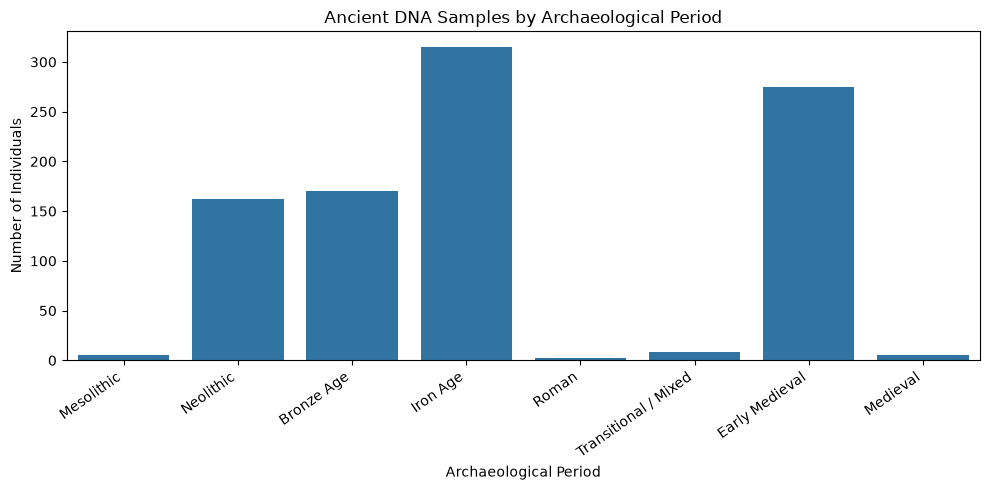

In [39]:
period_order = [
    "Mesolithic",
    "Neolithic",
    "Bronze Age",
    "Iron Age",
    "Roman",
    "Transitional / Mixed",
    "Early Medieval",
    "Medieval"
]

period_counts = (
    clean_samples["period"]
    .value_counts()
    .reindex(period_order)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=period_counts.index,
    y=period_counts.values
)

plt.title("Ancient DNA Samples by Archaeological Period")
plt.xlabel("Archaeological Period")
plt.ylabel("Number of Individuals")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    "images/plots/samples_by_period.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 29. Explore the Geographic Distribution of Samples

The geographic coordinates of the archaeological individuals are visualized to examine where samples are concentrated across Britain and Ireland. Samples are coloured by archaeological period to provide an initial view of spatial and chronological coverage.

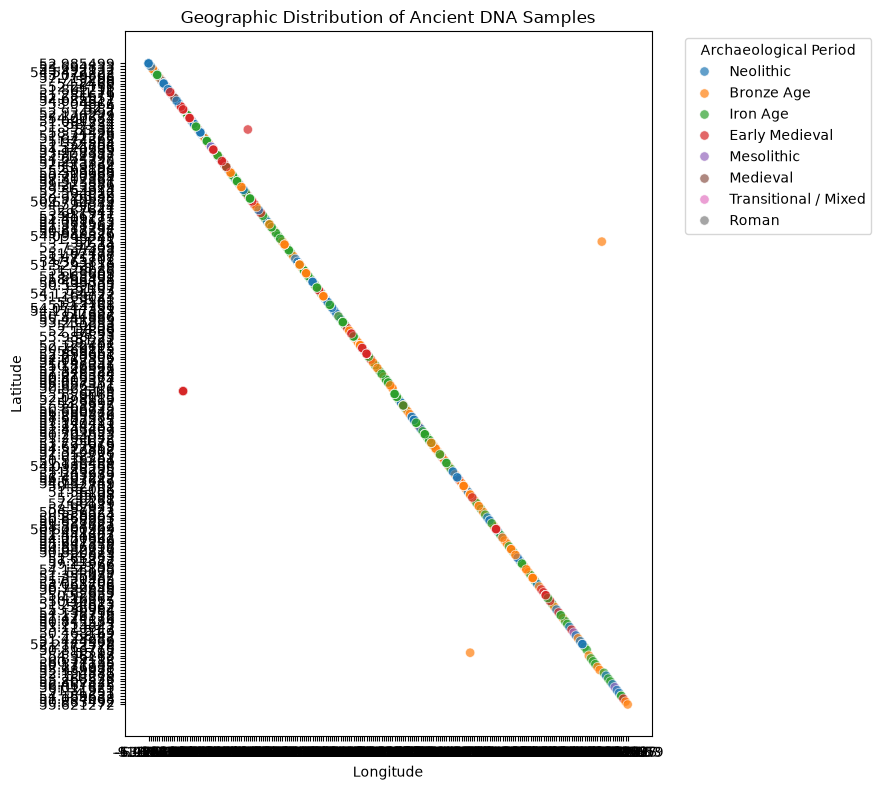

In [40]:
plt.figure(figsize=(9, 8))

sns.scatterplot(
    data=clean_samples,
    x="longitude",
    y="latitude",
    hue="period",
    alpha=0.7,
    s=45
)

plt.title("Geographic Distribution of Ancient DNA Samples")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "images/plots/geographic_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 30. Clean Geographic Coordinates

The first geographic plot revealed that latitude and longitude were being interpreted as text rather than numerical values. The coordinate columns are converted to numeric format, while invalid or missing values are replaced with missing values so they do not distort the spatial analysis.

In [41]:
clean_samples["latitude"] = pd.to_numeric(
    clean_samples["latitude"],
    errors="coerce"
)

clean_samples["longitude"] = pd.to_numeric(
    clean_samples["longitude"],
    errors="coerce"
)

print("Latitude type:", clean_samples["latitude"].dtype)
print("Longitude type:", clean_samples["longitude"].dtype)

print(
    "Samples with valid coordinates:",
    clean_samples[["latitude", "longitude"]].dropna().shape[0]
)

print(
    "Samples missing coordinates:",
    clean_samples[["latitude", "longitude"]].isna().any(axis=1).sum()
)

Latitude type: float64
Longitude type: float64
Samples with valid coordinates: 942
Samples missing coordinates: 0


## 31. Redraw the Geographic Distribution

After converting latitude and longitude to numeric values, the geographic distribution is plotted again. This provides a more reliable view of where archaeological samples are located across Britain and Ireland and how different archaeological periods are spatially represented.

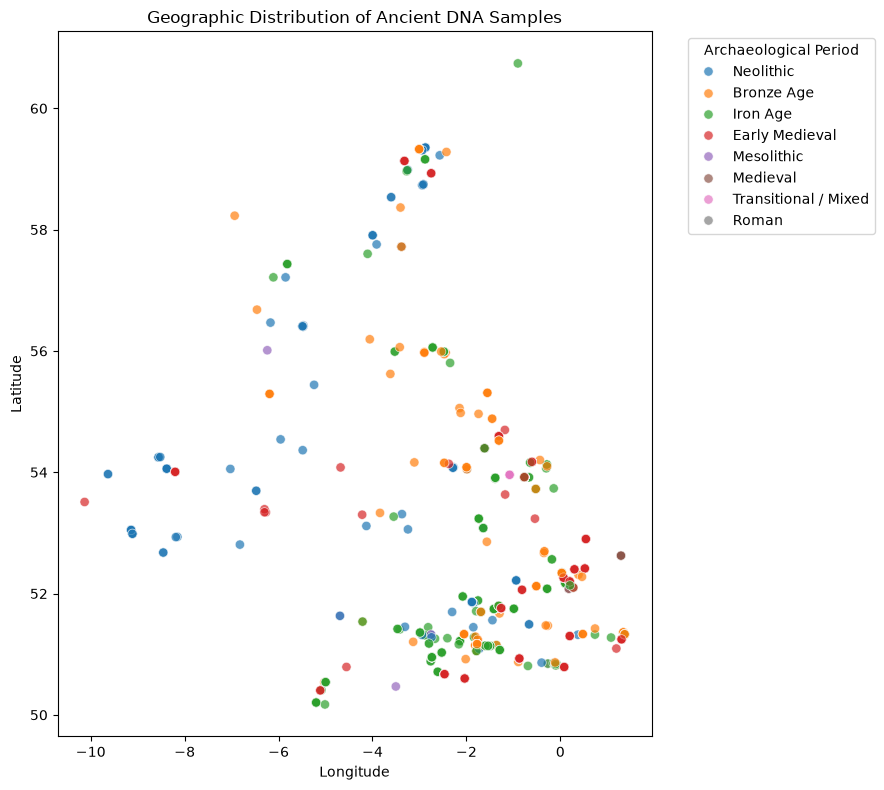

In [42]:
plt.figure(figsize=(9, 8))

sns.scatterplot(
    data=clean_samples,
    x="longitude",
    y="latitude",
    hue="period",
    alpha=0.7,
    s=45
)

plt.title("Geographic Distribution of Ancient DNA Samples")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "images/plots/geographic_distribution_clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 32. Save the Cleaned Archaeological Metadata

After quality filtering, duplicate removal, chronological classification, and coordinate cleaning, the final archaeological metadata is saved as a processed dataset. This file will be used later to connect archaeological information with the genetic genotype data.

In [43]:
output_path = "data/processed/britain_ireland_ancient_metadata.csv"

clean_samples.to_csv(
    output_path,
    index=False
)

print("Cleaned metadata saved successfully")
print("Saved samples:", clean_samples.shape[0])
print("Saved to:", output_path)

Cleaned metadata saved successfully
Saved samples: 942
Saved to: data/processed/britain_ireland_ancient_metadata.csv


## 33. Check the Genetic Data Files

The archaeological metadata describes each individual, but PCA and clustering require the underlying genotype data. Before beginning the genetic analysis, we check whether the required EIGENSTRAT genotype, individual, and SNP files are available in the project.

In [44]:
from pathlib import Path

genotype_files = {
    "Genotype": Path("data/raw/COMMIOS_aadr_HO_v62.geno.gz"),
    "Individuals": Path("data/raw/COMMIOS_aadr_HO_v62.ind.gz"),
    "SNPs": Path("data/raw/COMMIOS_aadr_HO_v62.snp.gz")
}

for name, path in genotype_files.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

Genotype: FOUND
Individuals: FOUND
SNPs: FOUND


## 35. Validate the Genetic Data Format

The genotype file is stored in a compressed binary representation rather than plain-text EIGENSTRAT format. Before extracting individuals or performing PCA, the genotype header is inspected in binary mode to identify the underlying format and confirm that the accompanying individual and SNP files can be read correctly.

In [45]:
import gzip

ind_path = "data/raw/COMMIOS_aadr_HO_v62.ind.gz"
snp_path = "data/raw/COMMIOS_aadr_HO_v62.snp.gz"
geno_path = "data/raw/COMMIOS_aadr_HO_v62.geno.gz"

# Count individuals
with gzip.open(ind_path, "rt", encoding="utf-8") as f:
    individual_count = sum(1 for _ in f)

# Count SNPs
with gzip.open(snp_path, "rt", encoding="utf-8") as f:
    snp_count = sum(1 for _ in f)

# Read genotype header as binary
with gzip.open(geno_path, "rb") as f:
    header = f.read(64)

if header.startswith(b"TGENO"):
    genotype_format = "TGENO"
elif header.startswith(b"GENO"):
    genotype_format = "PACKEDANCESTRYMAP / GENO"
else:
    genotype_format = "Unknown binary or text format"

print("Individuals in .ind:", individual_count)
print("SNPs in .snp:", snp_count)
print("Detected genotype format:", genotype_format)
print("First 48 header bytes:")
print(header[:48])

Individuals in .ind: 6872
SNPs in .snp: 584131
Detected genotype format: PACKEDANCESTRYMAP / GENO
First 48 header bytes:
b'GENO    6872  584131 cbf6939c 80974215\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'


## 36. Inspect the Genetic Individual File

The `.ind` file defines the individuals represented by the genotype matrix and determines their column order. We inspect its structure and compare its genetic IDs with the cleaned archaeological metadata before extracting genotype data.

In [46]:
ind_data = pd.read_csv(
    ind_path,
    sep=r"\s+",
    compression="gzip",
    header=None,
    names=["genetic_id", "sex", "population"]
)

print("Individuals loaded:", ind_data.shape[0])

ind_data.head(10)

Individuals loaded: 6872


,genetic_id,sex,population
0,I0001.AG,M,I0001.AG
1,CL146.AG,M,CL146.AG
2,CL23.AG,M,CL23.AG
3,CL25.AG,F,CL25.AG
4,CL30.AG,M,CL30.AG
5,CL36.AG,F,CL36.AG
6,CL38.AG,M,CL38.AG
7,CL47.AG,F,CL47.AG
8,CL53.AG,M,CL53.AG
9,CL57.AG,M,CL57.AG


## 37. Match Cleaned Archaeological Samples to the Genotype Matrix

The cleaned archaeological metadata contains 942 selected genetic representations. We compare these genetic IDs with the `.ind` file to confirm that every selected individual can be located in the genotype matrix before extracting genetic data.

In [47]:
selected_ids = set(clean_samples["genetic_id"])
genotype_ids = set(ind_data["genetic_id"])

matched_ids = selected_ids.intersection(genotype_ids)
missing_ids = selected_ids.difference(genotype_ids)

print("Selected archaeological individuals:", len(selected_ids))
print("Matched in genotype data:", len(matched_ids))
print("Missing from genotype data:", len(missing_ids))

if missing_ids:
    print("\nMissing IDs:")
    print(sorted(missing_ids))

Selected archaeological individuals: 942
Matched in genotype data: 942
Missing from genotype data: 0


## 38. Inspect the SNP Information File

The `.snp` file describes the genetic variants represented in the genotype matrix. Each row contains information such as the SNP identifier, chromosome, genetic position, physical position, and alleles. We inspect the file structure before extracting genotype data.

In [48]:
snp_data = pd.read_csv(
    snp_path,
    sep=r"\s+",
    compression="gzip",
    header=None
)

print("SNP records loaded:", snp_data.shape[0])
print("Number of columns:", snp_data.shape[1])

snp_data.head(10)

SNP records loaded: 584131
Number of columns: 6


,0,1,2,3,4,5
0,rs3094315,1,0.020130,752566,G,A
1,rs7419119,1,0.022518,842013,T,G
2,rs13302957,1,0.024116,891021,G,A
3,rs6696609,1,0.024457,903426,C,T
4,rs8997,1,0.025727,949654,A,G
5,rs9442372,1,0.026288,1018704,A,G
6,rs147606383,1,0.026665,1045331,G,A
7,rs4970405,1,0.026674,1048955,A,G
8,rs11807848,1,0.026711,1061166,T,C
9,rs4970421,1,0.028311,1108637,G,A


## 39. Label SNP Information and Identify Autosomal Variants

The SNP file contains six fields describing each genetic variant: SNP identifier, chromosome, genetic position, physical position, reference allele, and alternative allele. Since the main PCA analysis will focus on autosomal population structure, we first identify the variants located on chromosomes 1–22.

In [49]:
snp_data.columns = [
    "snp_id",
    "chromosome",
    "genetic_position",
    "physical_position",
    "allele_1",
    "allele_2"
]

autosomal_snps = snp_data[
    snp_data["chromosome"].between(1, 22)
].copy()

print("Total SNPs:", snp_data.shape[0])
print("Autosomal SNPs:", autosomal_snps.shape[0])
print("Non-autosomal SNPs:", snp_data.shape[0] - autosomal_snps.shape[0])

snp_data["chromosome"].value_counts().sort_index()

Total SNPs: 584131
Autosomal SNPs: 579720
Non-autosomal SNPs: 4411


chromosome
1     49770
2     51538
3     42953
4     35632
5     36773
6     35582
7     30184
8     30099
9     24879
10    31834
11    29520
12    28523
13    18621
14    19650
15    19044
16    19172
17    16142
18    17984
19     9189
20    16260
21     8317
22     8054
23     3814
24      597
Name: count, dtype: int64

## 40. Locate Selected Individuals in the Genotype Matrix

The packed genotype matrix stores individuals in the exact order defined by the `.ind` file. We therefore identify the column positions of the 942 selected archaeological individuals before extracting their genotype data.

In [50]:
selected_positions = ind_data.index[
    ind_data["genetic_id"].isin(clean_samples["genetic_id"])
].tolist()

print("Selected genotype columns:", len(selected_positions))
print("First 10 column positions:", selected_positions[:10])
print("Last 10 column positions:", selected_positions[-10:])

Selected genotype columns: 942
First 10 column positions: [47, 48, 49, 73, 74, 75, 76, 77, 80, 81]
Last 10 column positions: [5921, 5923, 5933, 5962, 6676, 6682, 6711, 6719, 6864, 6871]


## 41. Test Genotype Decoding

Before processing hundreds of thousands of SNPs, the packed genotype format is decoded for a single SNP. This small test confirms that individual positions, binary decoding, and missing-value handling are working correctly.

In [51]:
# PACKEDANCESTRYMAP stores 4 individuals per byte
record_size = max(48, (individual_count + 3) // 4)

def decode_genotype(block, sample_index):
    byte = block[sample_index // 4]
    shift = 6 - 2 * (sample_index % 4)
    return (byte >> shift) & 3

with gzip.open(geno_path, "rb") as f:
    header_block = f.read(record_size)
    first_snp_block = f.read(record_size)

first_selected_genotypes = np.array(
    [
        decode_genotype(first_snp_block, position)
        for position in selected_positions
    ],
    dtype=np.int8
)

values, counts = np.unique(
    first_selected_genotypes,
    return_counts=True
)

print("Packed record size:", record_size, "bytes")
print("First SNP:", snp_data.iloc[0]["snp_id"])

print("\nGenotype counts among selected individuals:")

labels = {
    0: "0 copies of reference allele",
    1: "1 copy of reference allele",
    2: "2 copies of reference allele",
    3: "Missing"
}

for value, count in zip(values, counts):
    print(f"{value} ({labels[value]}): {count}")

print("\nTotal decoded individuals:", len(first_selected_genotypes))

Packed record size: 1718 bytes
First SNP: rs3094315

Genotype counts among selected individuals:
0 (0 copies of reference allele): 433
2 (2 copies of reference allele): 78
3 (Missing): 431

Total decoded individuals: 942


## 42. Validate Genotype Decoding Across Multiple SNPs

Before processing the full genotype matrix, the decoding procedure is tested across a larger set of SNPs. This confirms that genotype values remain within the expected range and gives an initial estimate of missing genetic data among the selected archaeological individuals.

In [52]:
test_snp_count = 1000

decoded_test = []

with gzip.open(geno_path, "rb") as f:
    # Skip the packed header record
    f.read(record_size)

    for _ in range(test_snp_count):
        block = f.read(record_size)

        genotypes = [
            decode_genotype(block, position)
            for position in selected_positions
        ]

        decoded_test.append(genotypes)

decoded_test = np.array(decoded_test, dtype=np.int8)

print("Decoded matrix shape:", decoded_test.shape)

values, counts = np.unique(decoded_test, return_counts=True)

print("\nGenotype value counts:")

for value, count in zip(values, counts):
    print(f"{value}: {count}")

missing_rate = (decoded_test == 3).mean()

print("\nOverall missing rate:", round(missing_rate * 100, 2), "%")

Decoded matrix shape: (1000, 942)

Genotype value counts:
0: 142320
2: 429211
3: 370469

Overall missing rate: 39.33 %


## 43. Examine Missing Data Patterns

Ancient DNA datasets often contain substantial missing genotype information because DNA preservation and sequencing coverage vary between samples. We therefore examine missingness both across SNPs and across individuals before deciding on quality-control thresholds for PCA.

In [53]:
# Missingness for each SNP
snp_missing_rate = (decoded_test == 3).mean(axis=1)

# Missingness for each individual
individual_missing_rate = (decoded_test == 3).mean(axis=0)

print("SNP missingness:")
print(pd.Series(snp_missing_rate).describe())

print("\nIndividual missingness:")
print(pd.Series(individual_missing_rate).describe())

print(
    "\nSNPs with more than 50% missing data:",
    (snp_missing_rate > 0.50).sum()
)

print(
    "Individuals with more than 50% missing data:",
    (individual_missing_rate > 0.50).sum()
)

SNP missingness:
count    1000.000000
mean        0.393279
std         0.132018
min         0.227176
25%         0.298301
50%         0.345011
75%         0.458068
max         0.873673
dtype: float64

Individual missingness:
count    942.000000
mean       0.393279
std        0.308972
min        0.000000
25%        0.147000
50%        0.254500
75%        0.641500
max        0.998000
dtype: float64

SNPs with more than 50% missing data: 192
Individuals with more than 50% missing data: 288


## 44. Examine Genetic Coverage Across Individuals

Ancient DNA samples vary substantially in the number of genetic variants successfully recovered. The Human Origins SNP coverage provided in the metadata is examined to understand sample quality before defining a minimum coverage threshold for PCA and population-structure analysis.

In [54]:
print("Human Origins SNP coverage summary:")

clean_samples["ho_snps"].describe()

Human Origins SNP coverage summary:


count       942.000000
mean     309048.158174
std      163085.392647
min        2797.000000
25%      173224.250000
50%      373721.000000
75%      431409.750000
max      579690.000000
Name: ho_snps, dtype: float64

## 45. Evaluate Possible SNP Coverage Thresholds

Choosing a minimum SNP coverage involves a trade-off between retaining enough archaeological individuals and excluding samples with very sparse genetic information. Several possible thresholds are compared before selecting the quality-control cutoff for PCA.

In [55]:
coverage_thresholds = [
    50000,
    100000,
    150000,
    200000,
    250000,
    300000,
    400000
]

print("Coverage threshold | Individuals retained | Percentage retained")
print("-" * 62)

for threshold in coverage_thresholds:
    retained = (clean_samples["ho_snps"] >= threshold).sum()
    percentage = retained / clean_samples.shape[0] * 100

    print(
        f"{threshold:>17,} | "
        f"{retained:>20} | "
        f"{percentage:>18.1f}%"
    )

Coverage threshold | Individuals retained | Percentage retained
--------------------------------------------------------------
           50,000 |                  816 |               86.6%
          100,000 |                  753 |               79.9%
          150,000 |                  719 |               76.3%
          200,000 |                  687 |               72.9%
          250,000 |                  652 |               69.2%
          300,000 |                  595 |               63.2%
          400,000 |                  393 |               41.7%


## 46. Check Coverage Retention Across Archaeological Periods

A coverage threshold should not only retain a large number of individuals but also preserve representation across archaeological periods. We therefore compare how many samples from each period remain at several candidate SNP coverage thresholds.

In [56]:
candidate_thresholds = [50000, 100000, 150000, 200000]

for threshold in candidate_thresholds:
    print(f"\nMinimum HO SNPs: {threshold:,}")

    counts = (
        clean_samples.loc[
            clean_samples["ho_snps"] >= threshold,
            "period"
        ]
        .value_counts()
        .reindex(period_order, fill_value=0)
    )

    print(counts)


Minimum HO SNPs: 50,000
period
Mesolithic                3
Neolithic               146
Bronze Age              143
Iron Age                276
Roman                     2
Transitional / Mixed      8
Early Medieval          233
Medieval                  5
Name: count, dtype: int64

Minimum HO SNPs: 100,000
period
Mesolithic                2
Neolithic               134
Bronze Age              121
Iron Age                261
Roman                     2
Transitional / Mixed      8
Early Medieval          222
Medieval                  3
Name: count, dtype: int64

Minimum HO SNPs: 150,000
period
Mesolithic                2
Neolithic               131
Bronze Age              114
Iron Age                252
Roman                     2
Transitional / Mixed      8
Early Medieval          207
Medieval                  3
Name: count, dtype: int64

Minimum HO SNPs: 200,000
period
Mesolithic                1
Neolithic               126
Bronze Age              111
Iron Age                241
Roman  

## 47. Apply the Minimum Sample Coverage Threshold

A minimum coverage threshold of 50,000 Human Origins SNPs is used for the exploratory population-structure analysis. This relatively permissive threshold retains most individuals and helps preserve representation from archaeological periods with small sample sizes. Additional SNP-level quality control will be applied before PCA.

In [57]:
minimum_coverage = 50000

pca_samples = clean_samples[
    clean_samples["ho_snps"] >= minimum_coverage
].copy()

pca_positions = ind_data.index[
    ind_data["genetic_id"].isin(pca_samples["genetic_id"])
].tolist()

print("Samples before coverage filtering:", clean_samples.shape[0])
print("Samples retained for PCA:", pca_samples.shape[0])
print("Samples excluded:", clean_samples.shape[0] - pca_samples.shape[0])
print("Genotype positions identified:", len(pca_positions))

Samples before coverage filtering: 942
Samples retained for PCA: 816
Samples excluded: 126
Genotype positions identified: 816


## 48. Measure Missingness Across All Autosomal SNPs

Before PCA, genetic variants with excessive missing data should be identified. The packed genotype file is scanned across chromosomes 1–22 for the 816 retained individuals, and the missing-data rate is calculated for every autosomal SNP.

In [58]:
# Prepare fast vectorized decoding positions
pca_positions_array = np.array(pca_positions)

byte_indices = pca_positions_array // 4
bit_shifts = 6 - 2 * (pca_positions_array % 4)

# Identify autosomal SNP rows
autosomal_mask = snp_data["chromosome"].between(1, 22).to_numpy()

autosomal_missing_rates = []

with gzip.open(geno_path, "rb") as f:
    # Skip PACKEDANCESTRYMAP header record
    f.read(record_size)

    for snp_index in range(snp_count):
        block = f.read(record_size)

        if len(block) != record_size:
            raise ValueError(f"Unexpected end of genotype file at SNP {snp_index}")

        if autosomal_mask[snp_index]:
            packed = np.frombuffer(block, dtype=np.uint8)

            genotypes = (
                packed[byte_indices] >> bit_shifts
            ) & 3

            missing_rate = np.mean(genotypes == 3)
            autosomal_missing_rates.append(missing_rate)

autosomal_missing_rates = np.array(autosomal_missing_rates)

print("Autosomal SNPs analysed:", len(autosomal_missing_rates))

print("\nMissingness summary:")
print(pd.Series(autosomal_missing_rates).describe())

print("\nSNPs retained at different missingness limits:")

for limit in [0.10, 0.20, 0.30, 0.40, 0.50]:
    retained = np.sum(autosomal_missing_rates <= limit)

    print(
        f"≤ {int(limit * 100):2d}% missing: "
        f"{retained:,} SNPs "
        f"({retained / len(autosomal_missing_rates) * 100:.1f}%)"
    )

Autosomal SNPs analysed: 579720

Missingness summary:
count    579720.000000
mean          0.390768
std           0.189925
min           0.084559
25%           0.230392
50%           0.332108
75%           0.526961
max           0.993873
dtype: float64

SNPs retained at different missingness limits:
≤ 10% missing: 5 SNPs (0.0%)
≤ 20% missing: 79,636 SNPs (13.7%)
≤ 30% missing: 253,108 SNPs (43.7%)
≤ 40% missing: 350,087 SNPs (60.4%)
≤ 50% missing: 418,914 SNPs (72.3%)


## 49. Apply SNP-Level Missingness Filtering

For PCA, autosomal SNPs with more than 30% missing genotype calls are excluded. This threshold retains a large number of informative variants while reducing the influence of poorly covered SNPs that could distort population-structure analysis.

In [59]:
maximum_snp_missingness = 0.30

autosomal_indices = np.where(autosomal_mask)[0]

retained_autosomal_mask = (
    autosomal_missing_rates <= maximum_snp_missingness
)

retained_snp_indices = autosomal_indices[
    retained_autosomal_mask
]

print("Autosomal SNPs before filtering:", len(autosomal_indices))
print("SNPs retained after filtering:", len(retained_snp_indices))
print(
    "SNPs removed:",
    len(autosomal_indices) - len(retained_snp_indices)
)

print(
    "Percentage retained:",
    round(
        len(retained_snp_indices) /
        len(autosomal_indices) * 100,
        1
    ),
    "%"
)

Autosomal SNPs before filtering: 579720
SNPs retained after filtering: 253108
SNPs removed: 326612
Percentage retained: 43.7 %


## 50. Measure Individual Missingness After SNP Filtering

After SNP-level quality control, missingness is recalculated for each retained individual using only the 253,108 filtered autosomal SNPs. This helps identify samples that may still contain too little usable genetic information for reliable population-structure analysis.

In [60]:
retained_snp_mask = np.zeros(snp_count, dtype=bool)
retained_snp_mask[retained_snp_indices] = True

missing_counts_per_individual = np.zeros(
    len(pca_positions),
    dtype=np.int64
)

genotype_value_counts = np.zeros(4, dtype=np.int64)

with gzip.open(geno_path, "rb") as f:
    # Skip PACKEDANCESTRYMAP header
    f.read(record_size)

    for snp_index in range(snp_count):
        block = f.read(record_size)

        if retained_snp_mask[snp_index]:
            packed = np.frombuffer(block, dtype=np.uint8)

            genotypes = (
                packed[byte_indices] >> bit_shifts
            ) & 3

            missing_counts_per_individual += (genotypes == 3)

            genotype_value_counts += np.bincount(
                genotypes,
                minlength=4
            )

individual_missingness = (
    missing_counts_per_individual /
    len(retained_snp_indices)
)

print("Individual missingness after SNP filtering:")
print(pd.Series(individual_missingness).describe())

print("\nIndividuals above missingness thresholds:")

for limit in [0.20, 0.30, 0.40, 0.50]:
    count = np.sum(individual_missingness > limit)

    print(
        f"> {int(limit * 100):2d}% missing: "
        f"{count} individuals"
    )

print("\nGenotype value counts:")
for value, count in enumerate(genotype_value_counts):
    print(f"{value}: {count:,}")

Individual missingness after SNP filtering:
count    816.000000
mean       0.223619
std        0.259135
min        0.000004
25%        0.024514
50%        0.098227
75%        0.350163
max        0.909066
dtype: float64

Individuals above missingness thresholds:
> 20% missing: 305 individuals
> 30% missing: 239 individuals
> 40% missing: 181 individuals
> 50% missing: 144 individuals

Genotype value counts:
0: 40,577,755
1: 0
2: 119,772,932
3: 46,185,441


## 51. Evaluate Individual Missingness Thresholds by Archaeological Period

Ancient DNA preservation varies substantially between individuals. Before applying a final individual-level missingness threshold, several candidate cutoffs are compared to determine how many samples would remain in each archaeological period.

In [61]:
missingness_table = pca_samples.copy()

missingness_table["genotype_missingness"] = individual_missingness

candidate_limits = [0.30, 0.40, 0.50]

for limit in candidate_limits:
    print(f"\nMaximum individual missingness: {int(limit * 100)}%")

    retained = missingness_table[
        missingness_table["genotype_missingness"] <= limit
    ]

    counts = (
        retained["period"]
        .value_counts()
        .reindex(period_order, fill_value=0)
    )

    print("Total retained:", retained.shape[0])
    print(counts)


Maximum individual missingness: 30%
Total retained: 577
period
Mesolithic                3
Neolithic               107
Bronze Age               97
Iron Age                196
Roman                     1
Transitional / Mixed      3
Early Medieval          167
Medieval                  3
Name: count, dtype: int64

Maximum individual missingness: 40%
Total retained: 635
period
Mesolithic                3
Neolithic               117
Bronze Age              103
Iron Age                214
Roman                     1
Transitional / Mixed      6
Early Medieval          187
Medieval                  4
Name: count, dtype: int64

Maximum individual missingness: 50%
Total retained: 672
period
Mesolithic                3
Neolithic               122
Bronze Age              114
Iron Age                229
Roman                     1
Transitional / Mixed      6
Early Medieval          193
Medieval                  4
Name: count, dtype: int64


## 52. Apply the Final Individual Missingness Filter

A maximum individual missingness threshold of 40% is selected for the PCA dataset. This balances genetic data quality with sample retention, leaving 635 individuals while maintaining representation across most archaeological periods.

In [62]:
maximum_individual_missingness = 0.40

final_pca_samples = missingness_table[
    missingness_table["genotype_missingness"]
    <= maximum_individual_missingness
].copy()

final_pca_positions = ind_data.index[
    ind_data["genetic_id"].isin(final_pca_samples["genetic_id"])
].tolist()

print("Samples before individual filtering:", pca_samples.shape[0])
print("Final PCA samples:", final_pca_samples.shape[0])
print("Samples excluded:", pca_samples.shape[0] - final_pca_samples.shape[0])
print("Final genotype positions:", len(final_pca_positions))

print("\nSamples by archaeological period:")
print(
    final_pca_samples["period"]
    .value_counts()
    .reindex(period_order, fill_value=0)
)

Samples before individual filtering: 816
Final PCA samples: 635
Samples excluded: 181
Final genotype positions: 635

Samples by archaeological period:
period
Mesolithic                3
Neolithic               117
Bronze Age              103
Iron Age                214
Roman                     1
Transitional / Mixed      6
Early Medieval          187
Medieval                  4
Name: count, dtype: int64


## 53. Align Metadata with Genotype Column Order

The genotype matrix follows the individual order defined by the `.ind` file. To ensure that PCA coordinates are later matched to the correct archaeological individuals, the filtered metadata is reordered to follow the same genotype-column order.

In [63]:
final_genetic_ids = (
    ind_data.loc[final_pca_positions, "genetic_id"]
    .tolist()
)

final_pca_samples = (
    final_pca_samples
    .set_index("genetic_id")
    .loc[final_genetic_ids]
    .reset_index()
)

print("Final PCA samples:", final_pca_samples.shape[0])
print("Genotype positions:", len(final_pca_positions))

print(
    "Order aligned:",
    final_pca_samples["genetic_id"].tolist()
    == final_genetic_ids
)

final_pca_samples[
    ["genetic_id", "sample_id", "period", "ho_snps", "genotype_missingness"]
].head(10)

Final PCA samples: 635
Genotype positions: 635
Order aligned: True


,genetic_id,sample_id,period,ho_snps,genotype_missingness
0,I1767.AG,I1767,Bronze Age,386161,0.031165
1,I1774.AG,I1774,Bronze Age,52111,0.000004
2,I2417.AG,I2417,Bronze Age,432283,0.068552
3,I2458.AG,I2458,Bronze Age,436916,0.265009
4,I2461.AG,I2461,Bronze Age,415769,0.182242
5,I2462.AG,I2462,Bronze Age,439916,0.090250
6,I2566.AG,I2566,Bronze Age,262613,0.025424
7,I2567.AG,I2567,Bronze Age,320364,0.085691
8,I2568.AG,I2568,Bronze Age,307387,0.034705
9,I2573.AG,I2573,Bronze Age,331448,0.327485


## 54. Correctly Align Individual Missingness with Sample IDs

Individual missingness values were calculated in the column order of the genotype matrix. To ensure that each missingness value is assigned to the correct archaeological individual, the values are explicitly matched using the genetic ID before applying the final sample-quality filter.

In [64]:
# Genetic IDs in the exact order used when missingness was calculated
missingness_ids = (
    ind_data.loc[pca_positions, "genetic_id"]
    .tolist()
)

# Create an explicit ID-to-missingness table
missingness_by_id = pd.DataFrame({
    "genetic_id": missingness_ids,
    "genotype_missingness": individual_missingness
})

# Remove any previously assigned missingness column
pca_samples_corrected = pca_samples.drop(
    columns=["genotype_missingness"],
    errors="ignore"
)

# Match missingness to the correct individual by genetic ID
pca_samples_corrected = pca_samples_corrected.merge(
    missingness_by_id,
    on="genetic_id",
    how="left",
    validate="one_to_one"
)

print(
    "Samples with missing missingness values:",
    pca_samples_corrected["genotype_missingness"].isna().sum()
)

print("\nCorrected individual missingness:")
print(
    pca_samples_corrected["genotype_missingness"].describe()
)

print("\nIndividuals retained at candidate thresholds:")

for limit in [0.30, 0.40, 0.50]:
    retained = (
        pca_samples_corrected["genotype_missingness"] <= limit
    ).sum()

    print(
        f"≤ {int(limit * 100)}% missing: "
        f"{retained} individuals"
    )

Samples with missing missingness values: 0

Corrected individual missingness:
count    816.000000
mean       0.223619
std        0.259135
min        0.000004
25%        0.024514
50%        0.098227
75%        0.350163
max        0.909066
Name: genotype_missingness, dtype: float64

Individuals retained at candidate thresholds:
≤ 30% missing: 577 individuals
≤ 40% missing: 635 individuals
≤ 50% missing: 672 individuals


## 55. Rebuild the Final PCA Cohort with Correctly Matched Missingness

After correctly matching genotype missingness to each genetic ID, the final PCA cohort is rebuilt using the 40% missingness threshold. The metadata is then reordered to match the exact individual order used by the genotype matrix.

In [65]:
maximum_individual_missingness = 0.40

final_pca_samples = pca_samples_corrected[
    pca_samples_corrected["genotype_missingness"]
    <= maximum_individual_missingness
].copy()

final_pca_positions = ind_data.index[
    ind_data["genetic_id"].isin(final_pca_samples["genetic_id"])
].tolist()

final_genetic_ids = (
    ind_data.loc[final_pca_positions, "genetic_id"]
    .tolist()
)

final_pca_samples = (
    final_pca_samples
    .set_index("genetic_id")
    .loc[final_genetic_ids]
    .reset_index()
)

print("Final PCA samples:", final_pca_samples.shape[0])
print("Final genotype positions:", len(final_pca_positions))

print(
    "Order aligned:",
    final_pca_samples["genetic_id"].tolist()
    == final_genetic_ids
)

print("\nSamples by archaeological period:")
print(
    final_pca_samples["period"]
    .value_counts()
    .reindex(period_order, fill_value=0)
)

Final PCA samples: 635
Final genotype positions: 635
Order aligned: True

Samples by archaeological period:
period
Mesolithic                1
Neolithic               117
Bronze Age              103
Iron Age                231
Roman                     2
Transitional / Mixed      6
Early Medieval          172
Medieval                  3
Name: count, dtype: int64


## 56. Extract the Final Quality-Controlled Genotype Matrix

The final PCA dataset contains 635 archaeological individuals and 253,108 autosomal SNPs that passed quality-control filtering. The required genotype calls are extracted from the packed binary file and stored in a sample-by-SNP matrix. Missing genotype calls are represented as `-1` for easier processing in later steps.

In [66]:
final_positions_array = np.array(final_pca_positions)

final_byte_indices = final_positions_array // 4
final_bit_shifts = 6 - 2 * (final_positions_array % 4)

n_samples = len(final_pca_positions)
n_snps = len(retained_snp_indices)

genotype_matrix = np.empty(
    (n_samples, n_snps),
    dtype=np.int8
)

retained_lookup = np.zeros(snp_count, dtype=bool)
retained_lookup[retained_snp_indices] = True

column_index = 0

with gzip.open(geno_path, "rb") as f:
    # Skip PACKEDANCESTRYMAP header
    f.read(record_size)

    for snp_index in range(snp_count):
        block = f.read(record_size)

        if retained_lookup[snp_index]:
            packed = np.frombuffer(block, dtype=np.uint8)

            genotypes = (
                packed[final_byte_indices] >> final_bit_shifts
            ) & 3

            # Convert missing value 3 to -1
            genotypes = genotypes.astype(np.int8)
            genotypes[genotypes == 3] = -1

            genotype_matrix[:, column_index] = genotypes

            column_index += 1

print("Genotype matrix shape:", genotype_matrix.shape)
print("Matrix data type:", genotype_matrix.dtype)
print("SNPs extracted:", column_index)

values, counts = np.unique(
    genotype_matrix,
    return_counts=True
)

print("\nGenotype values:")
for value, count in zip(values, counts):
    print(f"{value}: {count:,}")

Genotype matrix shape: (635, 253108)
Matrix data type: int8
SNPs extracted: 253108

Genotype values:
-1: 16,185,365
0: 36,581,614
2: 107,956,601


## 57. Examine SNP Variation and Minor Allele Frequency

PCA is most informative when genetic variants contain variation across individuals. We therefore calculate the coded allele frequency for each SNP and examine how many variants are monomorphic or have very low minor allele frequency before deciding on a final SNP filter.

In [67]:
called_counts = np.count_nonzero(
    genotype_matrix != -1,
    axis=0
)

coded_allele_counts = np.count_nonzero(
    genotype_matrix == 2,
    axis=0
)

coded_allele_frequency = (
    coded_allele_counts / called_counts
)

minor_allele_frequency = np.minimum(
    coded_allele_frequency,
    1 - coded_allele_frequency
)

print("SNPs analysed:", len(minor_allele_frequency))

print("\nMinor allele frequency summary:")
print(pd.Series(minor_allele_frequency).describe())

print("\nSNP counts by MAF threshold:")

for threshold in [0.00, 0.01, 0.05, 0.10]:
    retained = np.sum(
        minor_allele_frequency > threshold
    )

    print(
        f"MAF > {threshold:.2f}: "
        f"{retained:,} SNPs"
    )

print(
    "\nMonomorphic SNPs:",
    np.sum(minor_allele_frequency == 0)
)

SNPs analysed: 253108

Minor allele frequency summary:
count    253108.000000
mean          0.171658
std           0.160451
min           0.000000
25%           0.011494
50%           0.134426
75%           0.307301
max           0.500000
dtype: float64

SNP counts by MAF threshold:
MAF > 0.00: 218,165 SNPs
MAF > 0.01: 191,610 SNPs
MAF > 0.05: 162,726 SNPs
MAF > 0.10: 140,557 SNPs

Monomorphic SNPs: 34943


## 58. Filter SNPs by Minor Allele Frequency

Variants that are monomorphic or extremely rare contribute little to broad population-structure analysis and may add noise to PCA. A minimum minor allele frequency of 5% is therefore applied, retaining common genetic variants for the next stage of analysis.

In [68]:
minimum_maf = 0.05

maf_mask = minor_allele_frequency > minimum_maf

pca_genotype_matrix = genotype_matrix[:, maf_mask]

pca_snp_indices = retained_snp_indices[maf_mask]

print("SNPs before MAF filtering:", genotype_matrix.shape[1])
print("SNPs after MAF filtering:", pca_genotype_matrix.shape[1])
print(
    "SNPs removed:",
    genotype_matrix.shape[1] - pca_genotype_matrix.shape[1]
)

print("\nPCA genotype matrix shape:")
print(pca_genotype_matrix.shape)

SNPs before MAF filtering: 253108
SNPs after MAF filtering: 162726
SNPs removed: 90382

PCA genotype matrix shape:
(635, 162726)


## 59. Impute Missing Genotypes

PCA cannot be performed directly with missing genotype values. For each SNP, missing calls are replaced with the mean genotype observed among individuals with available data at that variant. This preserves the average allele frequency of each SNP without assigning missing samples to a specific allele state.

In [69]:
pca_matrix = pca_genotype_matrix.astype(np.float32).copy()

missing_mask = pca_matrix == -1

# Calculate the mean genotype for each SNP using only observed calls
observed_matrix = np.where(
    missing_mask,
    np.nan,
    pca_matrix
)

snp_means = np.nanmean(
    observed_matrix,
    axis=0
)

# Replace missing values with the SNP mean
rows, cols = np.where(missing_mask)

pca_matrix[rows, cols] = snp_means[cols]

print("Matrix shape:", pca_matrix.shape)
print("Missing values before imputation:", missing_mask.sum())
print("Missing values after imputation:", np.isnan(pca_matrix).sum())

print(
    "Remaining -1 values:",
    np.sum(pca_matrix == -1)
)

Matrix shape: (635, 162726)
Missing values before imputation: 10441099
Missing values after imputation: 0
Remaining -1 values: 0


## 60. Reduce Closely Spaced SNPs Before PCA

Nearby genetic variants can be correlated because of linkage disequilibrium, causing some genomic regions to have too much influence on PCA. As a lightweight approximation to LD pruning, SNPs are thinned so that retained variants are at least 50 kb apart within each chromosome.

In [70]:
pca_snp_info = snp_data.iloc[pca_snp_indices].copy()
pca_snp_info["matrix_col"] = np.arange(len(pca_snp_indices))

minimum_distance = 50000

selected_matrix_columns = []

for chromosome in range(1, 23):
    chromosome_snps = (
        pca_snp_info[
            pca_snp_info["chromosome"] == chromosome
        ]
        .sort_values("physical_position")
    )

    last_position = -minimum_distance

    for _, row in chromosome_snps.iterrows():
        position = row["physical_position"]

        if position - last_position >= minimum_distance:
            selected_matrix_columns.append(
                int(row["matrix_col"])
            )

            last_position = position

selected_matrix_columns = np.array(
    selected_matrix_columns
)

thinned_pca_matrix = pca_matrix[
    :,
    selected_matrix_columns
]

print("SNPs before thinning:", pca_matrix.shape[1])
print("SNPs after thinning:", thinned_pca_matrix.shape[1])

print(
    "Percentage retained:",
    round(
        thinned_pca_matrix.shape[1] /
        pca_matrix.shape[1] * 100,
        1
    ),
    "%"
)

print("Final matrix shape:", thinned_pca_matrix.shape)

SNPs before thinning: 162726
SNPs after thinning: 33906
Percentage retained: 20.8 %
Final matrix shape: (635, 33906)


## 61. Standardize Genotypes for PCA

Genetic variants differ in their allele frequencies and therefore in their variance across individuals. Before PCA, each retained SNP is centered and scaled so that variants contribute more comparably to the population-structure analysis.

In [71]:
# Calculate the mean and standard deviation of each SNP
snp_mean = thinned_pca_matrix.mean(axis=0)
snp_std = thinned_pca_matrix.std(axis=0)

# Protect against division by zero
snp_std[snp_std == 0] = 1

# Standardize the genotype matrix
standardized_pca_matrix = (
    thinned_pca_matrix - snp_mean
) / snp_std

print("Standardized matrix shape:", standardized_pca_matrix.shape)

print(
    "Overall mean:",
    round(float(standardized_pca_matrix.mean()), 6)
)

print(
    "Overall standard deviation:",
    round(float(standardized_pca_matrix.std()), 6)
)

print(
    "NaN values:",
    np.isnan(standardized_pca_matrix).sum()
)


Standardized matrix shape: (635, 33906)
Overall mean: -0.0
Overall standard deviation: 1.0
NaN values: 0


## 62. Perform Principal Component Analysis

Principal Component Analysis (PCA) reduces the high-dimensional genotype dataset into a smaller number of components that capture the major patterns of genetic variation among individuals. The first principal components can therefore be used to explore broad population structure and genetic affinities within the ancient Britain and Ireland dataset.

In [72]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=10,
    svd_solver="randomized",
    random_state=42
)

pca_coordinates = pca.fit_transform(
    standardized_pca_matrix
)

print("PCA coordinate shape:", pca_coordinates.shape)

print("\nExplained variance:")
for i, variance in enumerate(
    pca.explained_variance_ratio_,
    start=1
):
    print(
        f"PC{i}: {variance * 100:.2f}%"
    )

print(
    "\nVariance explained by first 10 PCs:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

PCA coordinate shape: (635, 10)

Explained variance:
PC1: 0.64%
PC2: 0.30%
PC3: 0.26%
PC4: 0.24%
PC5: 0.23%
PC6: 0.22%
PC7: 0.22%
PC8: 0.21%
PC9: 0.21%
PC10: 0.21%

Variance explained by first 10 PCs: 2.73 %


## 63. Visualize the First Two Principal Components

The first two principal components are visualized to examine the strongest patterns of genetic variation among the ancient individuals. Samples are coloured by broad archaeological period to explore whether genetic structure corresponds with major chronological changes. Archaeological periods are used only as contextual labels and do not define the genetic clusters themselves.

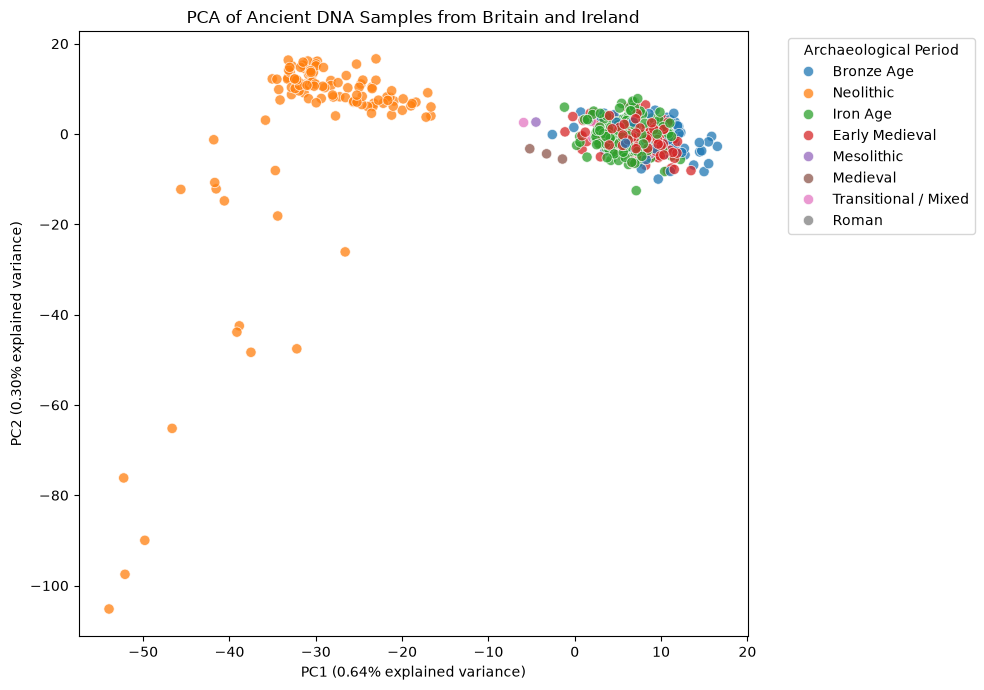

In [73]:
pca_results = final_pca_samples.copy()

pca_results["PC1"] = pca_coordinates[:, 0]
pca_results["PC2"] = pca_coordinates[:, 1]

pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_results,
    x="PC1",
    y="PC2",
    hue="period",
    s=55,
    alpha=0.75
)

plt.title("PCA of Ancient DNA Samples from Britain and Ireland")

plt.xlabel(
    f"PC1 ({pc1_variance:.2f}% explained variance)"
)

plt.ylabel(
    f"PC2 ({pc2_variance:.2f}% explained variance)"
)

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "images/plots/pca_pc1_pc2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 64. Check Whether PCA Structure Is Influenced by Missing Data

Extreme PCA positions can reflect genuine ancestry differences, but they can also arise from uneven ancient DNA coverage. We therefore test whether the first two principal components are associated with genotype missingness or SNP coverage before interpreting the observed population structure.

In [74]:
pc_qc = pca_results[
    [
        "genetic_id",
        "sample_id",
        "period",
        "PC1",
        "PC2",
        "ho_snps",
        "genotype_missingness"
    ]
].copy()

print("Correlation with genotype missingness:")
print(
    pc_qc[
        ["PC1", "PC2", "genotype_missingness"]
    ].corr()
)

print("\nCorrelation with HO SNP coverage:")
print(
    pc_qc[
        ["PC1", "PC2", "ho_snps"]
    ].corr()
)

print("\nMost extreme samples on PC2:")
display(
    pc_qc
    .assign(abs_PC2=pc_qc["PC2"].abs())
    .sort_values("abs_PC2", ascending=False)
    .head(15)
    .drop(columns="abs_PC2")
)

Correlation with genotype missingness:
                               PC1           PC2  genotype_missingness
PC1                   1.000000e+00  1.194209e-07             -0.009989
PC2                   1.194209e-07  1.000000e+00              0.015426
genotype_missingness -9.989140e-03  1.542647e-02              1.000000

Correlation with HO SNP coverage:
                  PC1           PC2   ho_snps
PC1      1.000000e+00  1.194209e-07 -0.265998
PC2      1.194209e-07  1.000000e+00 -0.013791
ho_snps -2.659976e-01 -1.379064e-02  1.000000

Most extreme samples on PC2:


,genetic_id,sample_id,period,PC1,PC2,ho_snps,genotype_missingness
574,I30300.TW,I30300,Neolithic,-53.954998,-105.178436,522187,0.055877
593,I30299.TW,I30299,Neolithic,-52.103794,-97.497650,551188,0.012512
312,I12440.AG,I12440,Neolithic,-49.811256,-89.975838,382443,0.043547
626,I21388.AG.TW,I21388,Neolithic,-52.256672,-76.159973,563872,0.005310
628,I21393.AG.TW,I21393,Neolithic,-46.645237,-65.190102,543464,0.016799
618,I13891.AG.TW,I13891,Neolithic,-37.513710,-48.340336,393351,0.085699
624,I12437.AG,I12437,Neolithic,-32.202030,-47.567356,273603,0.360356
627,I21389.AG.TW,I21389,Neolithic,-39.141674,-43.872936,458417,0.116685
578,I12439.AG,I12439,Neolithic,-38.859982,-42.484154,481586,0.000695
595,I30302.TW,I30302,Neolithic,-26.599024,-26.108286,371168,0.293570


## 65. Investigate the Neolithic PCA Outliers

Several Neolithic individuals occupy extreme positions on PC2 despite having relatively good genetic coverage. Their archaeological group labels and geographic origins are examined to determine whether the pattern corresponds to particular sites, populations, or genetic representations.

In [75]:
neolithic_outliers = (
    pca_results[pca_results["period"] == "Neolithic"]
    .assign(abs_PC2=lambda x: x["PC2"].abs())
    .sort_values("abs_PC2", ascending=False)
    .head(15)
)

neolithic_outliers[
    [
        "genetic_id",
        "sample_id",
        "group_id",
        "locality",
        "country",
        "date_bp",
        "PC1",
        "PC2",
        "ho_snps",
        "genotype_missingness"
    ]
]

,genetic_id,sample_id,group_id,locality,country,date_bp,PC1,PC2,ho_snps,genotype_missingness
574,I30300.TW,I30300,England_N_Megalithic.TW,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5575,-53.954998,-105.178436,522187,0.055877
593,I30299.TW,I30299,England_N_Megalithic_son.I30300.son.I30302.bro...,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5535,-52.103794,-97.497650,551188,0.012512
312,I12440.AG,I12440,England_N_Megalithic_son.I30300.son.I30302.bro...,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5600,-49.811256,-89.975838,382443,0.043547
626,I21388.AG.TW,I21388,England_N_Megalithic_son.I30300.son.I21390.AG.TW,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5657,-52.256672,-76.159973,563872,0.005310
628,I21393.AG.TW,I21393,England_N_Megalithic.AG.TW,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5600,-46.645237,-65.190102,543464,0.016799
618,I13891.AG.TW,I13891,England_N_Megalithic.AG.TW,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5526,-37.513710,-48.340336,393351,0.085699
624,I12437.AG,I12437,England_N_Megalithic_father.I13888.father.I213...,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5600,-32.202030,-47.567356,273603,0.360356
627,I21389.AG.TW,I21389,England_N_Megalithic.AG.TW,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5585,-39.141674,-43.872936,458417,0.116685
578,I12439.AG,I12439,England_N_Megalithic.AG,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5600,-38.859982,-42.484154,481586,0.000695
595,I30302.TW,I30302,England_N_Megalithic_son.I12437.brother.I13888...,"Hazleton North (England, Gloucestershire, Chel...",United Kingdom,5575,-26.599024,-26.108286,371168,0.293570


## 66. Check for Kinship and Site Concentration

The strongest Neolithic PCA outliers are concentrated at Hazleton North, and several population labels explicitly describe close family relationships. Because related individuals can strongly influence PCA, we examine the frequency of kinship-labelled samples and the representation of archaeological sites before interpreting the genetic structure.

In [76]:
relation_pattern = (
    "son|daughter|father|mother|brother|sister|"
    "rel\\.or\\.dup|relative|duplicate"
)

related_samples = pca_results[
    pca_results["group_id"].str.contains(
        relation_pattern,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Kinship-labelled samples:", related_samples.shape[0])

print("\nMost represented localities in the PCA dataset:")
print(
    pca_results["locality"]
    .value_counts()
    .head(15)
)

print("\nMost represented Neolithic localities:")
print(
    pca_results.loc[
        pca_results["period"] == "Neolithic",
        "locality"
    ]
    .value_counts()
    .head(15)
)

print("\nKinship-labelled samples by locality:")
print(
    related_samples["locality"]
    .value_counts()
    .head(15)
)

Kinship-labelled samples: 22

Most represented localities in the PCA dataset:
locality
West Heslerton (England, North Yorkshire, Vale of Pickering)    31
Pocklington (England, East Riding of Yorkshire)                 28
Hazleton North (England, Gloucestershire, Cheltenham)           27
Kilteasheen (County Roscommon)                                  24
East Kent Access Road (England, Kent, Ramsgate)                 22
St John's College Oxford (England, Oxford)                      15
Yarnton (England, Oxfordshire)                                  14
Hatherdene (England, Cambridgeshire)                            14
Cliffs End Farm (England, Kent, Ramsgate)                       13
Lakenheath (England, Suffolk)                                   12
Amesbury Down (England, Wiltshire)                              11
Oakington (England, Cambridgeshire)                             11
Rowbarrow (England, Wiltshire, Salisbury)                       11
Carsington Pasture Cave (England, Derbyshi

## 67. Inspect Hazleton North Individuals in Detail

Hazleton North contributes 27 Neolithic individuals and contains several samples with explicit kinship information in their population labels. Because this site is strongly represented among the PC2 outliers, all Hazleton North individuals are examined before deciding whether a kinship-based sensitivity analysis is required.

In [77]:
hazleton_samples = (
    pca_results[
        pca_results["locality"].str.contains(
            "Hazleton North",
            case=False,
            na=False
        )
    ]
    .copy()
    .sort_values("PC2")
)

print("Hazleton North individuals:", hazleton_samples.shape[0])

hazleton_samples[
    [
        "genetic_id",
        "sample_id",
        "group_id",
        "date_bp",
        "PC1",
        "PC2",
        "ho_snps",
        "genotype_missingness"
    ]
]

Hazleton North individuals: 27


,genetic_id,sample_id,group_id,date_bp,PC1,PC2,ho_snps,genotype_missingness
574,I30300.TW,I30300,England_N_Megalithic.TW,5575,-53.954998,-105.178436,522187,0.055877
593,I30299.TW,I30299,England_N_Megalithic_son.I30300.son.I30302.bro...,5535,-52.103794,-97.497650,551188,0.012512
312,I12440.AG,I12440,England_N_Megalithic_son.I30300.son.I30302.bro...,5600,-49.811256,-89.975838,382443,0.043547
626,I21388.AG.TW,I21388,England_N_Megalithic_son.I30300.son.I21390.AG.TW,5657,-52.256672,-76.159973,563872,0.005310
628,I21393.AG.TW,I21393,England_N_Megalithic.AG.TW,5600,-46.645237,-65.190102,543464,0.016799
618,I13891.AG.TW,I13891,England_N_Megalithic.AG.TW,5526,-37.513710,-48.340336,393351,0.085699
624,I12437.AG,I12437,England_N_Megalithic_father.I13888.father.I213...,5600,-32.202030,-47.567356,273603,0.360356
627,I21389.AG.TW,I21389,England_N_Megalithic.AG.TW,5585,-39.141674,-43.872936,458417,0.116685
578,I12439.AG,I12439,England_N_Megalithic.AG,5600,-38.859982,-42.484154,481586,0.000695
595,I30302.TW,I30302,England_N_Megalithic_son.I12437.brother.I13888...,5575,-26.599024,-26.108286,371168,0.293570


## 68. Check for Technical Effects from Genetic Data Representation

Several extreme PCA samples use `.TW` or `.AG.TW` genetic representations. Before interpreting PCA separation as biological population structure, we examine whether principal-component positions are associated with the type of genetic data representation used for each individual.

In [78]:
def get_representation(genetic_id):
    genetic_id = str(genetic_id)

    if ".TW" in genetic_id:
        return "TW-containing"
    elif ".SG" in genetic_id:
        return "SG"
    elif ".AG" in genetic_id:
        return "AG"
    elif ".DG" in genetic_id:
        return "DG"
    elif ".HO" in genetic_id:
        return "HO"
    else:
        return "Other"


pca_results["representation"] = (
    pca_results["genetic_id"]
    .apply(get_representation)
)

print("Samples by genetic representation:")
print(
    pca_results["representation"]
    .value_counts()
)

print("\nMean PCA coordinates by representation:")
print(
    pca_results
    .groupby("representation")
    .agg(
        samples=("genetic_id", "count"),
        mean_PC1=("PC1", "mean"),
        mean_PC2=("PC2", "mean"),
        median_PC2=("PC2", "median")
    )
    .sort_values("mean_PC2")
)

print("\nHazleton North samples by representation:")
print(
    pca_results.loc[
        pca_results["locality"].str.contains(
            "Hazleton North",
            case=False,
            na=False
        ),
        "representation"
    ].value_counts()
)

Samples by genetic representation:
representation
AG               491
SG               125
TW-containing     19
Name: count, dtype: int64

Mean PCA coordinates by representation:
                samples   mean_PC1   mean_PC2  median_PC2
representation                                           
TW-containing        19 -38.889584 -23.597609  -12.147717
AG                  491   3.835960  -0.062209   -0.210114
SG                  125  -9.156432   3.831195    2.531779

Hazleton North samples by representation:
representation
TW-containing    19
AG                8
Name: count, dtype: int64


## 69. Sensitivity Analysis Excluding TW-Containing Samples

All TW-containing genetic representations in the PCA dataset come from Hazleton North and show a strong shift in PC2. To test whether this technical representation is influencing the population structure, PCA is repeated after excluding TW-containing samples while keeping the same SNP set and preprocessing strategy.

Samples before exclusion: 635
TW-containing samples excluded: 19
Samples remaining: 616

Explained variance after excluding TW-containing samples:
PC1: 0.57%
PC2: 0.25%
PC3: 0.24%
PC4: 0.23%
PC5: 0.22%


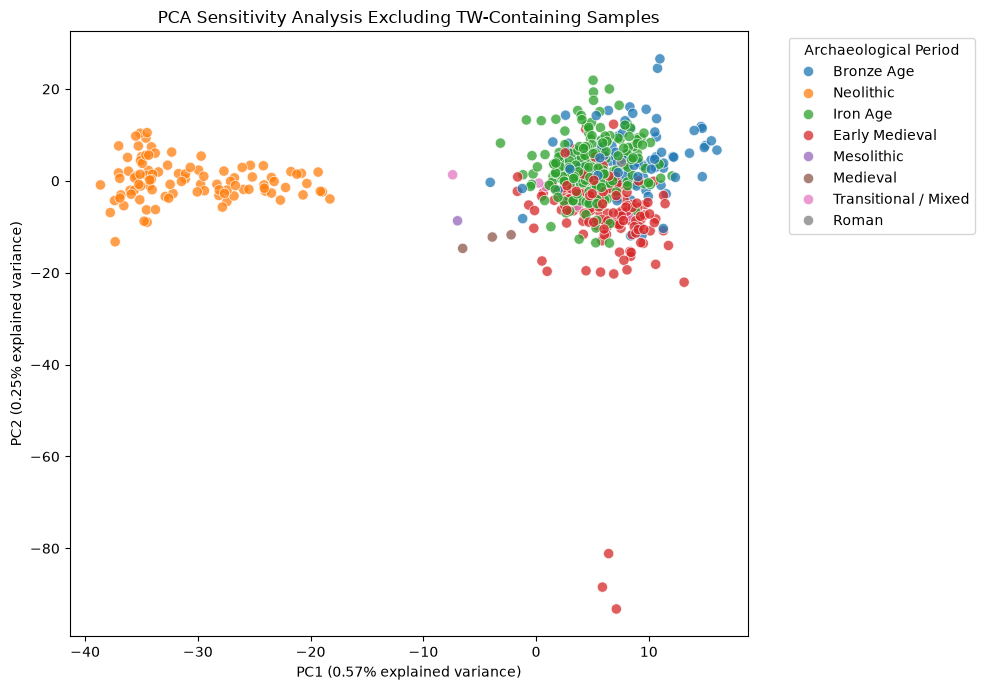

In [79]:
non_tw_mask = (
    pca_results["representation"] != "TW-containing"
).to_numpy()

non_tw_matrix = standardized_pca_matrix[
    non_tw_mask
]

non_tw_samples = pca_results.loc[
    non_tw_mask
].copy().reset_index(drop=True)

pca_non_tw = PCA(
    n_components=10,
    svd_solver="randomized",
    random_state=42
)

non_tw_coordinates = pca_non_tw.fit_transform(
    non_tw_matrix
)

non_tw_samples["PC1_nonTW"] = non_tw_coordinates[:, 0]
non_tw_samples["PC2_nonTW"] = non_tw_coordinates[:, 1]

print("Samples before exclusion:", pca_results.shape[0])
print("TW-containing samples excluded:", (~non_tw_mask).sum())
print("Samples remaining:", non_tw_samples.shape[0])

print("\nExplained variance after excluding TW-containing samples:")

for i, variance in enumerate(
    pca_non_tw.explained_variance_ratio_[:5],
    start=1
):
    print(f"PC{i}: {variance * 100:.2f}%")

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=non_tw_samples,
    x="PC1_nonTW",
    y="PC2_nonTW",
    hue="period",
    s=55,
    alpha=0.75
)

plt.title(
    "PCA Sensitivity Analysis Excluding TW-Containing Samples"
)

plt.xlabel(
    f"PC1 ({pca_non_tw.explained_variance_ratio_[0] * 100:.2f}% explained variance)"
)

plt.ylabel(
    f"PC2 ({pca_non_tw.explained_variance_ratio_[1] * 100:.2f}% explained variance)"
)

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

## 70. Investigate Extreme Samples After TW Exclusion

After removing TW-containing samples, the broad Neolithic separation remains, while a small number of Early Medieval individuals occupy extreme positions on PC2. These samples are inspected to determine whether their positions are associated with particular archaeological sites, population labels, sequencing representations, or data-quality characteristics.

In [80]:
extreme_non_tw = (
    non_tw_samples
    .assign(
        abs_PC2_nonTW=lambda x: x["PC2_nonTW"].abs()
    )
    .sort_values(
        "abs_PC2_nonTW",
        ascending=False
    )
    .head(15)
)

extreme_non_tw[
    [
        "genetic_id",
        "sample_id",
        "period",
        "group_id",
        "locality",
        "date_bp",
        "representation",
        "PC1_nonTW",
        "PC2_nonTW",
        "ho_snps",
        "genotype_missingness"
    ]
]

,genetic_id,sample_id,period,group_id,locality,date_bp,representation,PC1_nonTW,PC2_nonTW,ho_snps,genotype_missingness
146,LAK009.AG,LAK009,Early Medieval,England_Saxon.AG,"Lakenheath (England, Suffolk)",1200,AG,7.121175,-93.200325,439196,0.051950
141,LAK002.AG,LAK002,Early Medieval,England_Saxon.AG,"Lakenheath (England, Suffolk)",1200,AG,5.886735,-88.436256,471098,0.029497
150,LAK014.AG,LAK014,Early Medieval,England_Saxon.AG,"Lakenheath (England, Suffolk)",1200,AG,6.437562,-81.145584,365004,0.139292
107,I7580.AG,I7580,Bronze Age,England_MBA_lowEEF.AG,"Biddenham Loop (England, Bedfordshire)",3087,AG,10.985857,26.556604,419370,0.016649
106,I7579.AG,I7579,Bronze Age,England_MBA_sister.I7580.AG,"Biddenham Loop (England, Bedfordshire)",3349,AG,10.774405,24.509726,415278,0.021734
526,I20677.AG,I20677,Early Medieval,England_EarlyMedieval_Saxon.AG,"West Heslerton (England, North Yorkshire, Vale...",1450,AG,13.133750,-22.071745,461981,0.006464
85,I5506.AG,I5506,Iron Age,England_EastYorkshire_MIA.AG,"Pocklington (England, East Riding of Yorkshire)",2202,AG,5.059482,21.900112,448021,0.013077
509,I20646.AG,I20646,Early Medieval,England_EarlyMedieval_Saxon.AG,"West Heslerton (England, North Yorkshire, Vale...",1450,AG,6.890095,-20.262991,384824,0.066478
547,I21277.AG,I21277,Iron Age,England_MIA.AG,"Gravelly Guy (England, Oxfordshire, Stanton Ha...",2225,AG,6.501078,20.006874,457012,0.038576
51,I3044.AG,I3044,Early Medieval,England_EarlyMedieval_Saxon.AG,"Lincoln Castle (England, Lincolnshire, Lincoln)",856,AG,5.722809,-19.863672,401473,0.029339


## 71. Inspect Lakenheath Individuals

After excluding TW-containing samples, the strongest negative PC2 outliers are concentrated at Lakenheath. All individuals from this archaeological site are examined to determine whether the pattern is limited to a few samples or represents a broader site-specific genetic structure.

In [81]:
lakenheath_samples = (
    non_tw_samples[
        non_tw_samples["locality"].str.contains(
            "Lakenheath",
            case=False,
            na=False
        )
    ]
    .copy()
    .sort_values("PC2_nonTW")
)

print("Lakenheath individuals:", lakenheath_samples.shape[0])

print("\nPC2 summary for Lakenheath:")
print(
    lakenheath_samples["PC2_nonTW"].describe()
)

lakenheath_samples[
    [
        "genetic_id",
        "sample_id",
        "group_id",
        "date_bp",
        "PC1_nonTW",
        "PC2_nonTW",
        "ho_snps",
        "genotype_missingness"
    ]
]

Lakenheath individuals: 12

PC2 summary for Lakenheath:
count    12.000000
mean    -27.956657
std      36.762337
min     -93.200325
25%     -33.916199
50%     -13.118237
75%      -6.274683
max       8.651189
Name: PC2_nonTW, dtype: float64


,genetic_id,sample_id,group_id,date_bp,PC1_nonTW,PC2_nonTW,ho_snps,genotype_missingness
146,LAK009.AG,LAK009,England_Saxon.AG,1200,7.121175,-93.200325,439196,0.051950
141,LAK002.AG,LAK002,England_Saxon.AG,1200,5.886735,-88.436256,471098,0.029497
150,LAK014.AG,LAK014,England_Saxon.AG,1200,6.437562,-81.145584,365004,0.139292
140,LAK001.AG,LAK001,England_Saxon.AG,1200,10.609101,-18.173071,462676,0.031658
148,LAK011.AG,LAK011,England_Saxon.AG,1200,7.403310,-15.529809,455793,0.037126
151,LAK015.AG,LAK015,England_Saxon.AG,1200,8.326600,-15.370803,462046,0.045775
143,LAK005.AG,LAK005,England_Saxon.AG,1200,11.292810,-10.865672,417965,0.070361
142,LAK004.AG,LAK004,England_Saxon.AG,1200,7.069100,-8.951012,391807,0.106962
145,LAK008.AG,LAK008,England_Saxon.AG,1200,5.580292,-6.569633,361751,0.164369
147,LAK010.AG,LAK010,England_Saxon.AG,1200,8.096304,-5.389835,417112,0.071645


## 72. Sensitivity Analysis Excluding Lakenheath

Several Early Medieval individuals from Lakenheath occupy extreme positions on PC2 despite having good genetic coverage. To test whether this archaeological site is disproportionately influencing the second principal component, PCA is repeated after excluding all Lakenheath individuals.

Samples before Lakenheath exclusion: 616
Lakenheath samples excluded: 12
Samples remaining: 604

Explained variance:
PC1: 0.57%
PC2: 0.24%
PC3: 0.24%
PC4: 0.23%
PC5: 0.22%


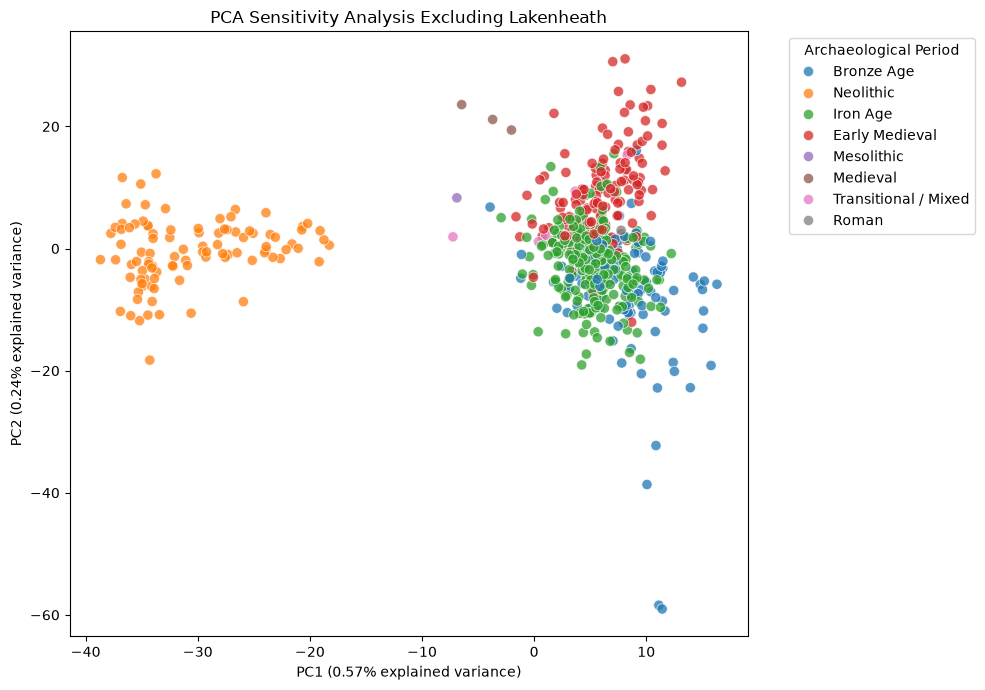

In [82]:
lakenheath_mask = (
    non_tw_samples["locality"]
    .str.contains(
        "Lakenheath",
        case=False,
        na=False
    )
    .to_numpy()
)

non_lakenheath_matrix = non_tw_matrix[
    ~lakenheath_mask
]

non_lakenheath_samples = (
    non_tw_samples.loc[
        ~lakenheath_mask
    ]
    .copy()
    .reset_index(drop=True)
)

pca_no_lakenheath = PCA(
    n_components=10,
    svd_solver="randomized",
    random_state=42
)

coordinates_no_lakenheath = (
    pca_no_lakenheath.fit_transform(
        non_lakenheath_matrix
    )
)

non_lakenheath_samples["PC1_clean"] = (
    coordinates_no_lakenheath[:, 0]
)

non_lakenheath_samples["PC2_clean"] = (
    coordinates_no_lakenheath[:, 1]
)

print("Samples before Lakenheath exclusion:", non_tw_samples.shape[0])
print("Lakenheath samples excluded:", lakenheath_mask.sum())
print("Samples remaining:", non_lakenheath_samples.shape[0])

print("\nExplained variance:")
for i, variance in enumerate(
    pca_no_lakenheath.explained_variance_ratio_[:5],
    start=1
):
    print(f"PC{i}: {variance * 100:.2f}%")

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=non_lakenheath_samples,
    x="PC1_clean",
    y="PC2_clean",
    hue="period",
    s=55,
    alpha=0.75
)

plt.title(
    "PCA Sensitivity Analysis Excluding Lakenheath"
)

plt.xlabel(
    f"PC1 ({pca_no_lakenheath.explained_variance_ratio_[0] * 100:.2f}% explained variance)"
)

plt.ylabel(
    f"PC2 ({pca_no_lakenheath.explained_variance_ratio_[1] * 100:.2f}% explained variance)"
)

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "images/plots/pca_sensitivity_no_tw_no_lakenheath.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 73. Summarize PCA Structure by Archaeological Period

To quantify the patterns visible in the sensitivity PCA, the mean and spread of PC1 and PC2 are calculated for each archaeological period. This provides a numerical summary of how the major chronological groups are positioned within the genetic variation captured by the first two principal components.

In [83]:
period_pca_summary = (
    non_lakenheath_samples
    .groupby("period")
    .agg(
        samples=("genetic_id", "count"),
        mean_PC1=("PC1_clean", "mean"),
        std_PC1=("PC1_clean", "std"),
        mean_PC2=("PC2_clean", "mean"),
        std_PC2=("PC2_clean", "std")
    )
    .reindex(period_order)
)

period_pca_summary.round(2)

,samples,mean_PC1,std_PC1,mean_PC2,std_PC2
period,,,,,
Mesolithic,1,-6.890000,NaN,8.310000,NaN
Neolithic,98,-30.549999,5.41,-0.550000,5.21
Bronze Age,103,8.000000,3.78,-7.390000,10.49
Iron Age,231,5.300000,2.50,-2.590000,5.76
Roman,2,5.580000,3.08,1.720000,1.81
Transitional / Mixed,6,1.930000,5.35,5.160000,5.90
Early Medieval,160,5.880000,2.76,8.170000,7.34
Medieval,3,-4.060000,2.24,21.379999,2.09


## 74. Define the Main PCA Analysis Dataset

Sensitivity analyses showed that TW-containing samples had a strong association with the extreme PCA pattern at Hazleton North. These records are excluded from the main downstream analysis to reduce potential technical confounding. Lakenheath individuals are retained because their PCA pattern may represent genuine site-specific genetic structure rather than poor data quality.

The resulting PCA dataset therefore contains the quality-controlled non-TW individuals, while the analyses excluding Lakenheath are retained only as a sensitivity check.

In [84]:
main_pca_samples = non_tw_samples.copy()
main_pca_matrix = non_tw_matrix.copy()

print("Main PCA individuals:", main_pca_samples.shape[0])
print("Genetic features:", main_pca_matrix.shape[1])

print("\nSamples by archaeological period:")
print(
    main_pca_samples["period"]
    .value_counts()
    .reindex(period_order, fill_value=0)
)

print("\nGenetic representations:")
print(
    main_pca_samples["representation"]
    .value_counts()
)

Main PCA individuals: 616
Genetic features: 33906

Samples by archaeological period:
period
Mesolithic                1
Neolithic                98
Bronze Age              103
Iron Age                231
Roman                     2
Transitional / Mixed      6
Early Medieval          172
Medieval                  3
Name: count, dtype: int64

Genetic representations:
representation
AG    491
SG    125
Name: count, dtype: int64


## 75. Reprocess Genotypes for the Final PCA Cohort

Because the TW-containing individuals were excluded after the initial genotype preprocessing, missing-value imputation and SNP standardization are recalculated using only the 616 individuals retained in the main analysis. This prevents the excluded samples from influencing the allele means and variance used in the final PCA.

In [85]:
# Return to the MAF-filtered genotype matrix before imputation
# and keep only the SNPs selected during thinning
main_raw_matrix = (
    pca_genotype_matrix[non_tw_mask][:, selected_matrix_columns]
    .astype(np.float32)
    .copy()
)

# Identify missing calls
main_missing_mask = main_raw_matrix == -1

# Calculate SNP means using only observed genotypes
main_observed = np.where(
    main_missing_mask,
    np.nan,
    main_raw_matrix
)

main_snp_means = np.nanmean(
    main_observed,
    axis=0
)

# Impute missing genotypes with the SNP mean
rows, cols = np.where(main_missing_mask)

main_raw_matrix[rows, cols] = main_snp_means[cols]

# Recalculate mean and standard deviation using only
# the final 616 individuals
main_mean = main_raw_matrix.mean(axis=0)
main_std = main_raw_matrix.std(axis=0)

zero_variance_snps = np.sum(main_std == 0)

main_std[main_std == 0] = 1

main_pca_matrix = (
    main_raw_matrix - main_mean
) / main_std

print("Final matrix shape:", main_pca_matrix.shape)
print("Missing values:", np.isnan(main_pca_matrix).sum())
print("Zero-variance SNPs:", zero_variance_snps)
print("Overall mean:", round(float(main_pca_matrix.mean()), 6))
print(
    "Overall standard deviation:",
    round(float(main_pca_matrix.std()), 6)
)

Final matrix shape: (616, 33906)
Missing values: 0
Zero-variance SNPs: 0
Overall mean: 0.0
Overall standard deviation: 1.0


## 76. Run the Final Principal Component Analysis

The final PCA is performed on the fully quality-controlled dataset of 616 ancient individuals and 33,906 genome-wide SNPs. Missing-value imputation and standardization were recalculated after removing the TW-containing samples, ensuring that excluded records do not influence the final population-structure analysis.

Final PCA coordinate shape: (616, 10)

Explained variance:
PC1: 0.57%
PC2: 0.25%
PC3: 0.24%
PC4: 0.23%
PC5: 0.22%
PC6: 0.22%
PC7: 0.22%
PC8: 0.21%
PC9: 0.21%
PC10: 0.21%

Variance explained by first 10 PCs: 2.57 %


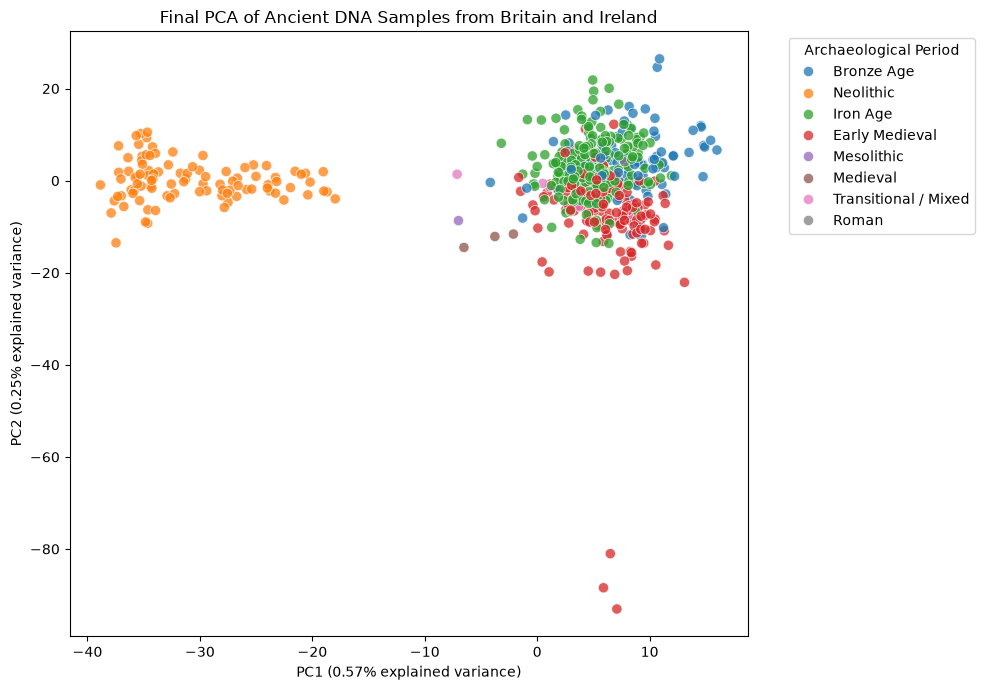

In [86]:
final_pca = PCA(
    n_components=10,
    svd_solver="randomized",
    random_state=42
)

final_coordinates = final_pca.fit_transform(
    main_pca_matrix
)

main_pca_samples["PC1_final"] = final_coordinates[:, 0]
main_pca_samples["PC2_final"] = final_coordinates[:, 1]

print("Final PCA coordinate shape:", final_coordinates.shape)

print("\nExplained variance:")
for i, variance in enumerate(
    final_pca.explained_variance_ratio_,
    start=1
):
    print(f"PC{i}: {variance * 100:.2f}%")

print(
    "\nVariance explained by first 10 PCs:",
    round(
        final_pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=main_pca_samples,
    x="PC1_final",
    y="PC2_final",
    hue="period",
    s=55,
    alpha=0.75
)

plt.title(
    "Final PCA of Ancient DNA Samples from Britain and Ireland"
)

plt.xlabel(
    f"PC1 ({final_pca.explained_variance_ratio_[0] * 100:.2f}% explained variance)"
)

plt.ylabel(
    f"PC2 ({final_pca.explained_variance_ratio_[1] * 100:.2f}% explained variance)"
)

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "images/plots/final_pca_pc1_pc2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 77. Visualize Explained Variance Across Principal Components

The proportion of genetic variation captured by each principal component is examined before clustering. Because genome-wide datasets contain thousands of correlated sources of variation, individual principal components may explain only a small percentage of the total variance while still capturing meaningful population structure.

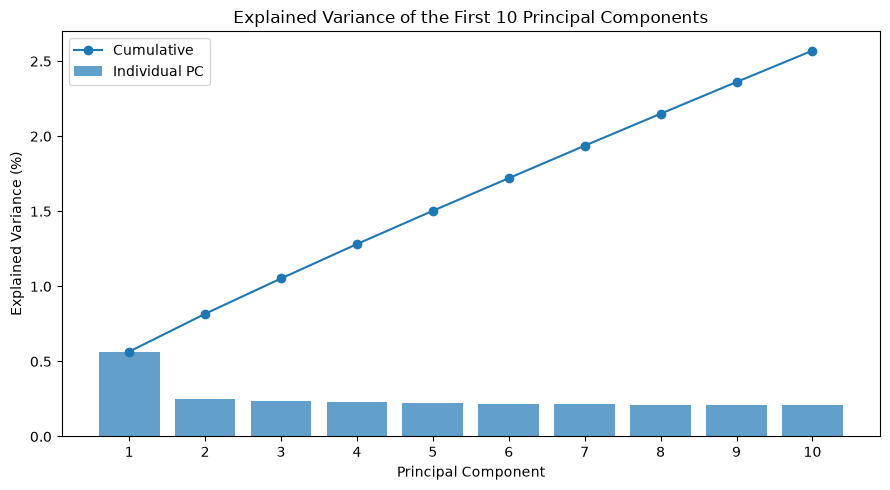

Cumulative variance explained by PC1-PC10: 2.57%


In [87]:
pc_numbers = np.arange(
    1,
    len(final_pca.explained_variance_ratio_) + 1
)

explained_percent = (
    final_pca.explained_variance_ratio_ * 100
)

cumulative_percent = np.cumsum(
    explained_percent
)

plt.figure(figsize=(9, 5))

plt.bar(
    pc_numbers,
    explained_percent,
    alpha=0.7,
    label="Individual PC"
)

plt.plot(
    pc_numbers,
    cumulative_percent,
    marker="o",
    label="Cumulative"
)

plt.xticks(pc_numbers)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")

plt.title(
    "Explained Variance of the First 10 Principal Components"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "images/plots/pca_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Cumulative variance explained by PC1-PC10:",
    f"{cumulative_percent[-1]:.2f}%"
)

## 78. Evaluate the Number of Genetic Clusters

Unsupervised clustering can reveal groups of individuals with similar positions in PCA space, but the number of clusters should not be chosen arbitrarily. K-Means clustering is tested across several values of `k`, and the silhouette score is used to compare how clearly separated the resulting clusters are.

The first 10 principal components are used so that clustering is not based only on the two dimensions shown in the PCA plot.

In [88]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = final_coordinates[:, :10]

k_values = range(2, 9)

silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(cluster_features)

    score = silhouette_score(
        cluster_features,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"k = {k}: "
        f"silhouette score = {score:.4f}"
    )

k = 2: silhouette score = 0.3158
k = 3: silhouette score = 0.1436
k = 4: silhouette score = 0.1400
k = 5: silhouette score = 0.1439
k = 6: silhouette score = 0.1390
k = 7: silhouette score = 0.1264
k = 8: silhouette score = 0.1502


## 79. Fit the Two-Cluster K-Means Model

The silhouette analysis indicates that two clusters provide the clearest separation among the tested solutions. A K-Means model with `k = 2` is therefore fitted to the first 10 principal components.

The resulting clusters are treated as data-driven genetic groupings and are not assigned archaeological or ancestry labels until their composition has been examined.

In [89]:
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

cluster_labels = final_kmeans.fit_predict(
    final_coordinates[:, :10]
)

main_pca_samples["cluster"] = cluster_labels

print("Cluster sizes:")
print(
    main_pca_samples["cluster"]
    .value_counts()
    .sort_index()
)

print("\nArchaeological periods within each cluster:")

cluster_period_table = pd.crosstab(
    main_pca_samples["cluster"],
    main_pca_samples["period"]
)

cluster_period_table

Cluster sizes:
cluster
0     98
1    518
Name: count, dtype: int64

Archaeological periods within each cluster:


period,Bronze Age,Early Medieval,Iron Age,Medieval,Mesolithic,Neolithic,Roman,Transitional / Mixed
cluster,,,,,,,,
0,0,0,0,0,0,98,0,0
1,103,172,231,3,1,0,2,6


## 80. Visualize the Data-Driven Genetic Clusters

The two-cluster K-Means solution separates all Neolithic individuals from the later archaeological samples. The clusters are visualized in PCA space to confirm how closely the unsupervised genetic grouping corresponds to the major structure observed along PC1.

These clusters represent statistical genetic structure and should not be interpreted as direct evidence of specific migrations or population replacement without additional archaeological and genetic evidence.

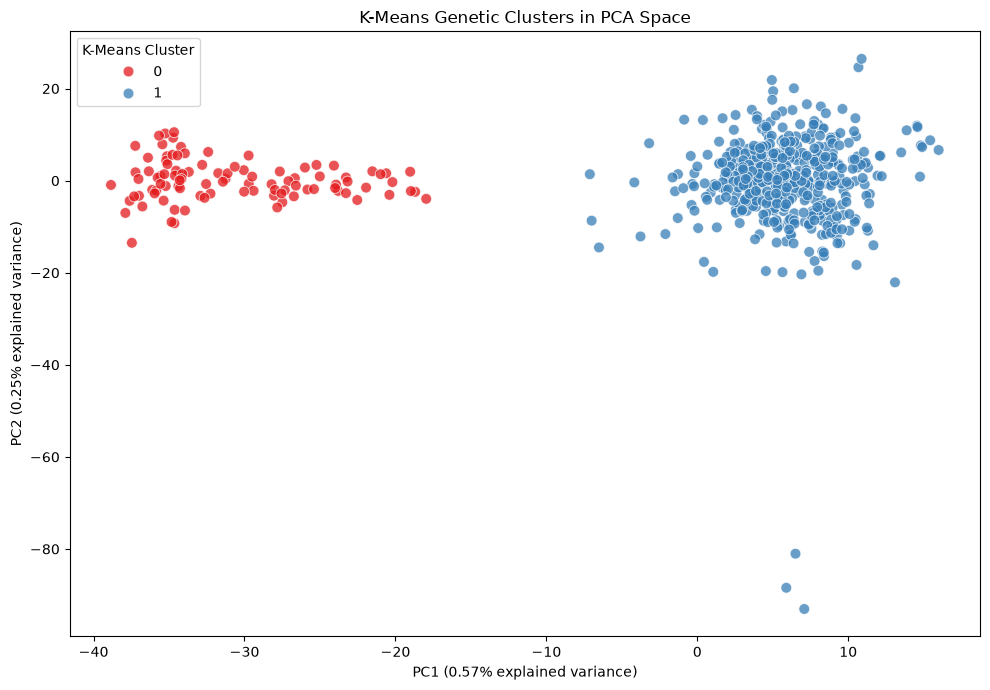

In [90]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=main_pca_samples,
    x="PC1_final",
    y="PC2_final",
    hue="cluster",
    palette="Set1",
    s=60,
    alpha=0.75
)

plt.title(
    "K-Means Genetic Clusters in PCA Space"
)

plt.xlabel(
    f"PC1 ({final_pca.explained_variance_ratio_[0] * 100:.2f}% explained variance)"
)

plt.ylabel(
    f"PC2 ({final_pca.explained_variance_ratio_[1] * 100:.2f}% explained variance)"
)

plt.legend(
    title="K-Means Cluster"
)

plt.tight_layout()

plt.savefig(
    "images/plots/kmeans_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 81. Create a Post-Neolithic Dataset for Finer Population Analysis

The two-cluster model primarily separates Neolithic individuals from later populations. To investigate more subtle genetic structure among Bronze Age, Iron Age, Roman, and Medieval populations, a secondary dataset is created containing only post-Neolithic individuals.

The single Mesolithic individual is also excluded from this secondary analysis because one sample is insufficient to represent Mesolithic population structure.

In [91]:
post_neolithic_mask = ~main_pca_samples["period"].isin(
    ["Mesolithic", "Neolithic"]
)

post_neolithic_samples = (
    main_pca_samples.loc[post_neolithic_mask]
    .copy()
    .reset_index(drop=True)
)

post_neolithic_raw = (
    main_raw_matrix[post_neolithic_mask]
    .copy()
)

print("Post-Neolithic individuals:", post_neolithic_samples.shape[0])

print("\nSamples by archaeological period:")
print(
    post_neolithic_samples["period"]
    .value_counts()
    .reindex(period_order, fill_value=0)
)

Post-Neolithic individuals: 517

Samples by archaeological period:
period
Mesolithic                0
Neolithic                 0
Bronze Age              103
Iron Age                231
Roman                     2
Transitional / Mixed      6
Early Medieval          172
Medieval                  3
Name: count, dtype: int64


## 82. Reprocess Genotypes for the Post-Neolithic Analysis

To study finer genetic structure after the Neolithic period, genotype preprocessing is repeated using only the 517 post-Neolithic individuals. Missing-value imputation and SNP standardization are recalculated within this subset so that the strong Neolithic genetic separation does not influence the secondary PCA.

In [92]:
# Start again from the MAF-filtered genotype calls before imputation
post_neolithic_genotypes = (
    pca_genotype_matrix[non_tw_mask][post_neolithic_mask]
    [:, selected_matrix_columns]
    .astype(np.float32)
    .copy()
)

# Identify missing genotype calls
post_missing_mask = post_neolithic_genotypes == -1

# Calculate SNP means using only observed post-Neolithic genotypes
post_observed = np.where(
    post_missing_mask,
    np.nan,
    post_neolithic_genotypes
)

post_snp_means = np.nanmean(
    post_observed,
    axis=0
)

# Check for SNPs with no observed calls
all_missing_snps = np.isnan(post_snp_means)

print("SNPs with no observed calls:", all_missing_snps.sum())

# Remove any completely missing SNPs if present
post_neolithic_genotypes = post_neolithic_genotypes[
    :,
    ~all_missing_snps
]

post_missing_mask = post_missing_mask[
    :,
    ~all_missing_snps
]

post_snp_means = post_snp_means[
    ~all_missing_snps
]

# Impute remaining missing values
rows, cols = np.where(post_missing_mask)

post_neolithic_genotypes[rows, cols] = post_snp_means[cols]

# Standardize SNPs
post_mean = post_neolithic_genotypes.mean(axis=0)
post_std = post_neolithic_genotypes.std(axis=0)

zero_variance = post_std == 0

print("Zero-variance SNPs:", zero_variance.sum())

post_neolithic_genotypes = post_neolithic_genotypes[
    :,
    ~zero_variance
]

post_mean = post_mean[~zero_variance]
post_std = post_std[~zero_variance]

post_neolithic_matrix = (
    post_neolithic_genotypes - post_mean
) / post_std

print("Final post-Neolithic matrix:", post_neolithic_matrix.shape)
print("NaN values:", np.isnan(post_neolithic_matrix).sum())
print("Overall mean:", round(float(post_neolithic_matrix.mean()), 6))
print(
    "Overall standard deviation:",
    round(float(post_neolithic_matrix.std()), 6)
)

SNPs with no observed calls: 0
Zero-variance SNPs: 0
Final post-Neolithic matrix: (517, 33906)
NaN values: 0
Overall mean: -0.0
Overall standard deviation: 1.0


## 83. Perform PCA on Post-Neolithic Populations

A second PCA is performed using only post-Neolithic individuals. Removing the strong Neolithic genetic separation allows more subtle patterns among Bronze Age, Iron Age, Roman, and Medieval populations to become visible.

This analysis is exploratory and describes genetic structure rather than directly identifying migration events or ancestry sources.

Post-Neolithic PCA shape: (517, 10)

Explained variance:
PC1: 0.30%
PC2: 0.28%
PC3: 0.27%
PC4: 0.26%
PC5: 0.26%
PC6: 0.25%
PC7: 0.25%
PC8: 0.25%
PC9: 0.25%
PC10: 0.24%

Variance explained by first 10 PCs: 2.62 %


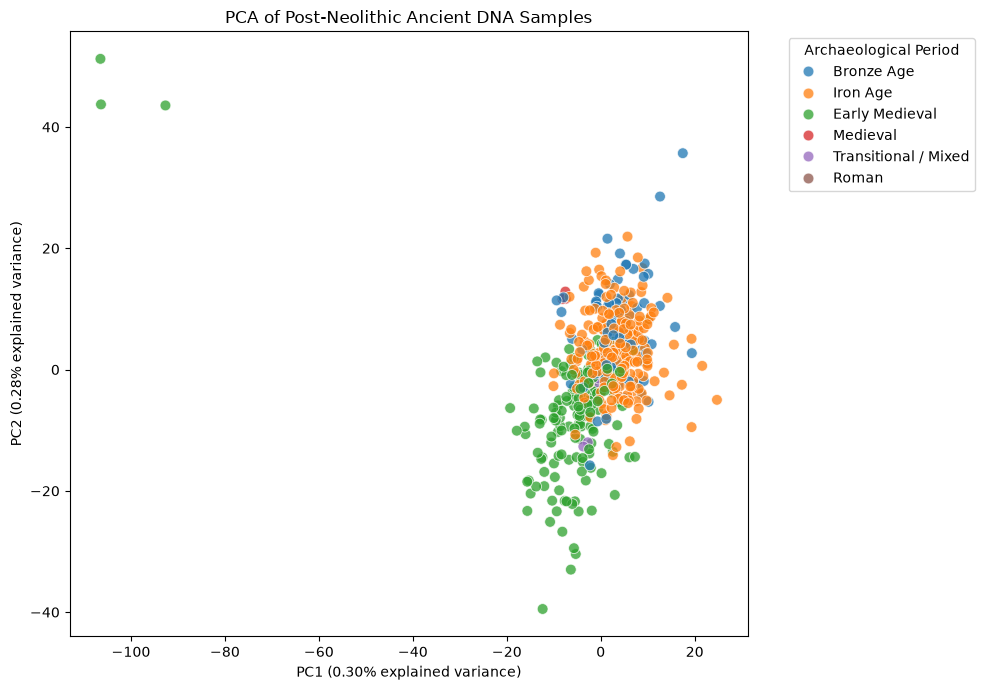

In [93]:
post_pca = PCA(
    n_components=10,
    svd_solver="randomized",
    random_state=42
)

post_coordinates = post_pca.fit_transform(
    post_neolithic_matrix
)

post_neolithic_samples["PC1_post"] = post_coordinates[:, 0]
post_neolithic_samples["PC2_post"] = post_coordinates[:, 1]

print("Post-Neolithic PCA shape:", post_coordinates.shape)

print("\nExplained variance:")
for i, variance in enumerate(
    post_pca.explained_variance_ratio_,
    start=1
):
    print(f"PC{i}: {variance * 100:.2f}%")

print(
    "\nVariance explained by first 10 PCs:",
    round(
        post_pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=post_neolithic_samples,
    x="PC1_post",
    y="PC2_post",
    hue="period",
    s=60,
    alpha=0.75
)

plt.title(
    "PCA of Post-Neolithic Ancient DNA Samples"
)

plt.xlabel(
    f"PC1 ({post_pca.explained_variance_ratio_[0] * 100:.2f}% explained variance)"
)

plt.ylabel(
    f"PC2 ({post_pca.explained_variance_ratio_[1] * 100:.2f}% explained variance)"
)

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "images/plots/post_neolithic_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 84. Evaluate Genetic Clusters in the Post-Neolithic Dataset

After removing the dominant Neolithic separation, potential genetic structure among the later populations is evaluated using K-Means clustering. Several values of `k` are compared using the silhouette score to determine whether the post-Neolithic samples form clearly separated genetic groups.

The first 10 principal components are used so that clustering reflects multidimensional genetic variation rather than only PC1 and PC2.

In [94]:
post_cluster_features = post_coordinates[:, :10]

post_k_values = range(2, 9)
post_silhouette_scores = []

for k in post_k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        post_cluster_features
    )

    score = silhouette_score(
        post_cluster_features,
        labels
    )

    post_silhouette_scores.append(score)

    print(
        f"k = {k}: "
        f"silhouette score = {score:.4f}"
    )

k = 2: silhouette score = 0.6888
k = 3: silhouette score = 0.0852
k = 4: silhouette score = 0.0907
k = 5: silhouette score = 0.0846
k = 6: silhouette score = 0.0786
k = 7: silhouette score = 0.0856
k = 8: silhouette score = 0.0927


## 85. Inspect the Two Post-Neolithic Genetic Clusters

The two-cluster solution produces a high silhouette score, but a strong score can sometimes result from a small group of unusually distant individuals. Before interpreting the clusters biologically, their sizes, archaeological periods, and most common localities are examined.

In [95]:
post_kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

post_cluster_labels = post_kmeans_2.fit_predict(
    post_cluster_features
)

post_neolithic_samples["post_cluster"] = post_cluster_labels

print("Cluster sizes:")
print(
    post_neolithic_samples["post_cluster"]
    .value_counts()
    .sort_index()
)

print("\nArchaeological periods by cluster:")

print(
    pd.crosstab(
        post_neolithic_samples["post_cluster"],
        post_neolithic_samples["period"]
    )
)

print("\nMost common localities in Cluster 0:")
print(
    post_neolithic_samples.loc[
        post_neolithic_samples["post_cluster"] == 0,
        "locality"
    ]
    .value_counts()
    .head(10)
)

print("\nMost common localities in Cluster 1:")
print(
    post_neolithic_samples.loc[
        post_neolithic_samples["post_cluster"] == 1,
        "locality"
    ]
    .value_counts()
    .head(10)
)

Cluster sizes:
post_cluster
0    514
1      3
Name: count, dtype: int64

Archaeological periods by cluster:
period        Bronze Age  Early Medieval  Iron Age  Medieval  Roman  \
post_cluster                                                          
0                    103             169       231         3      2   
1                      0               3         0         0      0   

period        Transitional / Mixed  
post_cluster                        
0                                6  
1                                0  

Most common localities in Cluster 0:
locality
West Heslerton (England, North Yorkshire, Vale of Pickering)    31
Pocklington (England, East Riding of Yorkshire)                 28
Kilteasheen (County Roscommon)                                  24
East Kent Access Road (England, Kent, Ramsgate)                 22
St John's College Oxford (England, Oxford)                      15
Yarnton (England, Oxfordshire)                                  14
Hatherdene

## 86. Test Post-Neolithic Structure Without the Lakenheath Outlier Cluster

The apparent two-cluster solution is driven entirely by three Early Medieval individuals from Lakenheath. Rather than interpreting this small site-specific group as a major population division, a sensitivity analysis is performed after excluding these three individuals.

Genotype preprocessing and PCA are recalculated within the remaining samples before cluster numbers are evaluated again.

In [96]:
# Keep the large post-Neolithic cluster
core_mask = (
    post_neolithic_samples["post_cluster"] == 0
).to_numpy()

core_samples = (
    post_neolithic_samples.loc[core_mask]
    .copy()
    .reset_index(drop=True)
)

# Return to raw post-Neolithic genotype calls
core_genotypes = (
    pca_genotype_matrix[non_tw_mask][post_neolithic_mask]
    [core_mask][:, selected_matrix_columns]
    .astype(np.float32)
    .copy()
)

# Impute missing values again
core_missing = core_genotypes == -1

core_observed = np.where(
    core_missing,
    np.nan,
    core_genotypes
)

core_snp_means = np.nanmean(
    core_observed,
    axis=0
)

rows, cols = np.where(core_missing)
core_genotypes[rows, cols] = core_snp_means[cols]

# Standardize again using only these individuals
core_mean = core_genotypes.mean(axis=0)
core_std = core_genotypes.std(axis=0)

valid_snps = core_std > 0

core_matrix = (
    core_genotypes[:, valid_snps]
    - core_mean[valid_snps]
) / core_std[valid_snps]

# Recalculate PCA
core_pca = PCA(
    n_components=10,
    svd_solver="randomized",
    random_state=42
)

core_coordinates = core_pca.fit_transform(
    core_matrix
)

print("Individuals in sensitivity analysis:", core_samples.shape[0])
print("SNPs retained:", core_matrix.shape[1])

print("\nSilhouette scores after excluding the 3-person cluster:")

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        core_coordinates[:, :10]
    )

    score = silhouette_score(
        core_coordinates[:, :10],
        labels
    )

    print(
        f"k = {k}: "
        f"silhouette score = {score:.4f}"
    )

Individuals in sensitivity analysis: 514
SNPs retained: 33906

Silhouette scores after excluding the 3-person cluster:
k = 2: silhouette score = 0.0838
k = 3: silhouette score = 0.0791
k = 4: silhouette score = 0.0751
k = 5: silhouette score = 0.0821
k = 6: silhouette score = 0.0763
k = 7: silhouette score = 0.0801
k = 8: silhouette score = 0.0887


## 87. Finalize PCA and Clustering Results

The clustering sensitivity analysis showed that the strong post-Neolithic two-cluster solution was driven by only three Lakenheath individuals. After excluding this small site-specific group, silhouette scores were low across all tested values of `k`, indicating no strong evidence for discrete genetic clusters among the remaining post-Neolithic individuals.

Therefore, the main population-structure result is interpreted primarily through PCA rather than forcing additional K-Means clusters. The final PCA coordinates are now attached to the archaeological metadata and saved for later interpretation and visualization.

In [97]:
# Add all 10 final principal components to the main results table
for i in range(10):
    main_pca_samples[f"PC{i + 1}"] = final_coordinates[:, i]

# Keep the main two-cluster result as an exploratory label
main_pca_samples["kmeans_cluster"] = cluster_labels

# Flag the Lakenheath samples identified during sensitivity analysis
main_pca_samples["lakenheath_site"] = (
    main_pca_samples["locality"]
    .str.contains(
        "Lakenheath",
        case=False,
        na=False
    )
)

output_path = "data/processed/final_pca_results.csv"

main_pca_samples.to_csv(
    output_path,
    index=False
)

print("Final PCA results saved successfully")
print("Individuals:", main_pca_samples.shape[0])
print("Principal components saved: 10")
print("Saved to:", output_path)

print("\nK-Means cluster sizes:")
print(
    main_pca_samples["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

Final PCA results saved successfully
Individuals: 616
Principal components saved: 10
Saved to: data/processed/final_pca_results.csv

K-Means cluster sizes:
kmeans_cluster
0     98
1    518
Name: count, dtype: int64


## 88. Examine Genetic Structure Through Time

The first principal component captures the strongest genetic distinction in the dataset, particularly the separation between Neolithic and later individuals. PC1 is plotted against archaeological date to examine how this genetic structure changes through time.

This visualization shows temporal genetic patterns but should not by itself be interpreted as proof of a specific migration or population replacement event.

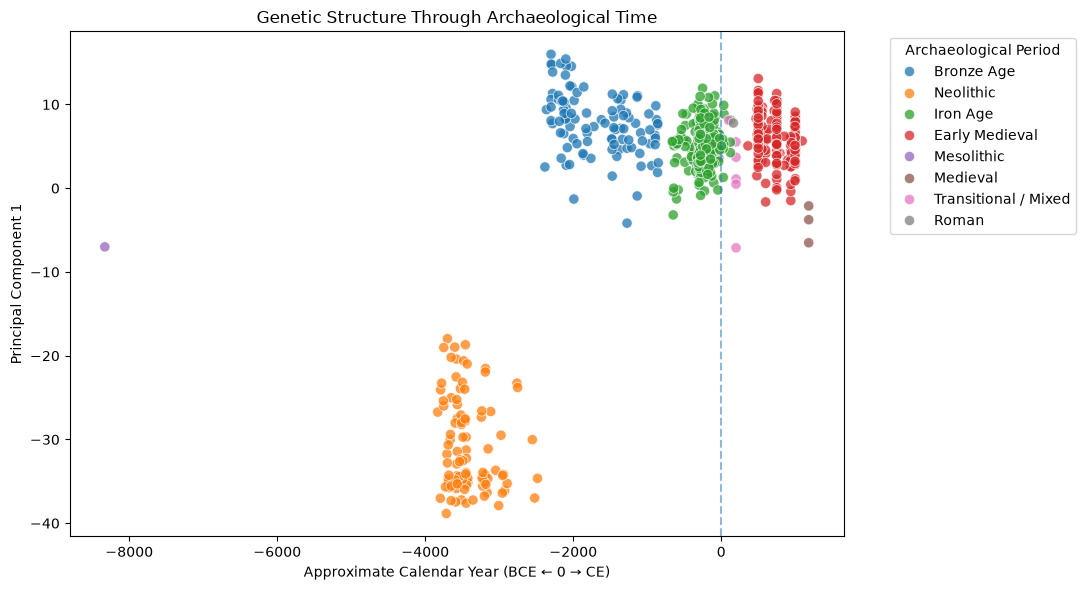

In [98]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=main_pca_samples,
    x="calendar_year",
    y="PC1",
    hue="period",
    s=55,
    alpha=0.75
)

plt.axvline(
    x=0,
    linestyle="--",
    alpha=0.5
)

plt.title(
    "Genetic Structure Through Archaeological Time"
)

plt.xlabel(
    "Approximate Calendar Year (BCE ← 0 → CE)"
)

plt.ylabel(
    "Principal Component 1"
)

plt.legend(
    title="Archaeological Period",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "images/plots/genetic_structure_through_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 89. Summarize Genetic Change Across Archaeological Periods

To quantify the temporal pattern visible in the PCA, PC1 is summarized for each archaeological period. The sample count, median, mean, and spread of PC1 provide a numerical description of how genetic structure differs through time.

Periods represented by very few individuals should be interpreted cautiously.

In [99]:
temporal_summary = (
    main_pca_samples
    .groupby("period")
    .agg(
        samples=("genetic_id", "count"),
        median_PC1=("PC1", "median"),
        mean_PC1=("PC1", "mean"),
        std_PC1=("PC1", "std"),
        earliest_year=("calendar_year", "min"),
        latest_year=("calendar_year", "max")
    )
    .reindex(period_order)
)

temporal_summary = temporal_summary.round(2)

temporal_summary

,samples,median_PC1,mean_PC1,std_PC1,earliest_year,latest_year
period,,,,,,
Mesolithic,1,-7.00,-7.000000,NaN,-8330,-8330
Neolithic,98,-32.59,-30.690001,5.56,-3831,-2483
Bronze Age,103,7.77,7.770000,3.71,-2383,-851
Iron Age,231,4.98,5.080000,2.46,-662,125
Roman,2,5.69,5.690000,2.96,-31,164
Transitional / Mixed,6,2.40,1.970000,5.27,100,200
Early Medieval,172,5.91,5.990000,2.70,361,1094
Medieval,3,-3.76,-4.130000,2.22,1182,1182


## 90. Save the Archaeological Period Summary

The period-level PCA summary is saved as a processed output so that the main temporal patterns can be reproduced and referenced independently of the notebook.

The strongest pattern is the large separation between the Neolithic samples and the later archaeological periods along PC1. Differences among the post-Neolithic periods are comparatively smaller and more overlapping.

In [100]:
summary_path = "data/processed/period_pca_summary.csv"

temporal_summary.to_csv(
    summary_path
)

print("Period PCA summary saved successfully.")
print("Saved to:", summary_path)

print("\nMain analytical dataset:")
print("Individuals:", len(main_pca_samples))
print("Genetic features used for PCA:", main_pca_matrix.shape[1])

print("\nMain temporal result:")
print(
    "Neolithic mean PC1:",
    round(
        main_pca_samples.loc[
            main_pca_samples["period"] == "Neolithic",
            "PC1"
        ].mean(),
        2
    )
)

print(
    "Bronze Age mean PC1:",
    round(
        main_pca_samples.loc[
            main_pca_samples["period"] == "Bronze Age",
            "PC1"
        ].mean(),
        2
    )
)

Period PCA summary saved successfully.
Saved to: data/processed/period_pca_summary.csv

Main analytical dataset:
Individuals: 616
Genetic features used for PCA: 33906

Main temporal result:
Neolithic mean PC1: -30.69
Bronze Age mean PC1: 7.77


## 91. Compare PC1 Across Archaeological Periods

The distribution of PC1 scores is compared across archaeological periods to summarize the strongest temporal pattern identified by the PCA.

The Neolithic samples occupy a clearly different region of PC1 space, while Bronze Age, Iron Age, Roman, and Early Medieval individuals show substantially greater overlap. Periods represented by very small sample sizes should be interpreted cautiously.

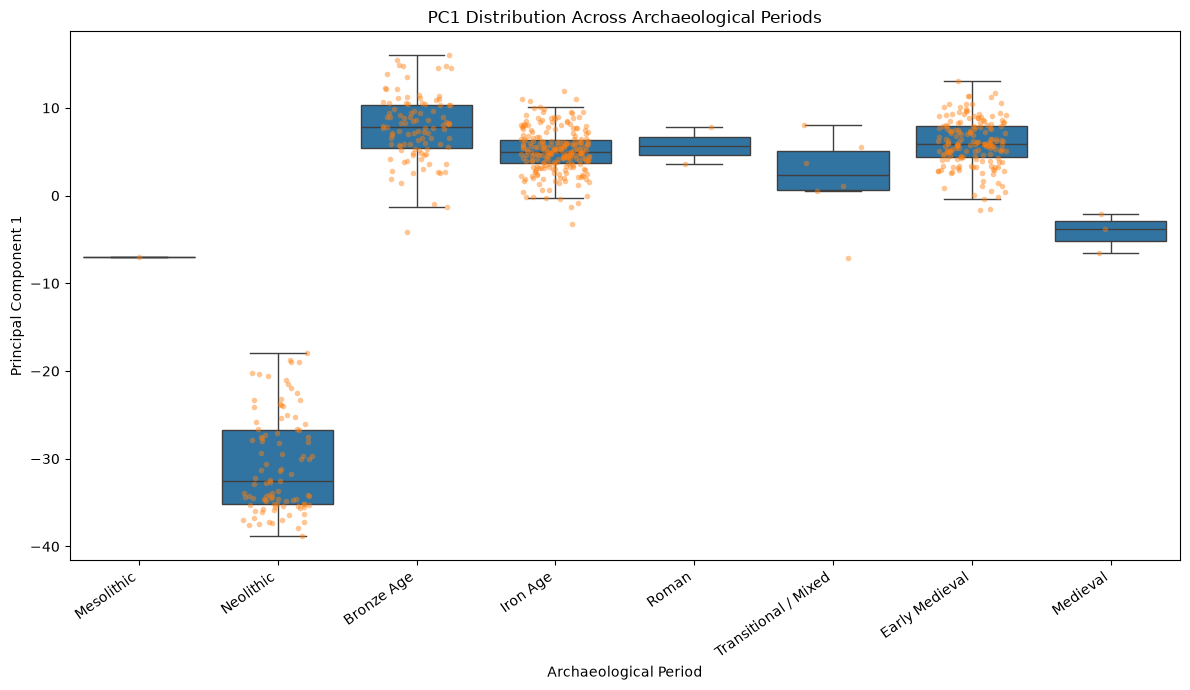

In [101]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=main_pca_samples,
    x="period",
    y="PC1",
    order=period_order,
    showfliers=False
)

sns.stripplot(
    data=main_pca_samples,
    x="period",
    y="PC1",
    order=period_order,
    alpha=0.45,
    size=4,
    jitter=0.25
)

plt.title(
    "PC1 Distribution Across Archaeological Periods"
)

plt.xlabel(
    "Archaeological Period"
)

plt.ylabel(
    "Principal Component 1"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "images/plots/pc1_by_archaeological_period.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 92. Final Analytical Summary

After quality control and genotype filtering, the main analysis included 616 ancient individuals and 33,906 genetic variants from Britain and Ireland.

PCA identified a pronounced separation between Neolithic individuals and later archaeological populations. The Neolithic group had a mean PC1 score of approximately -30.69, compared with 7.77 for the Bronze Age. Bronze Age, Iron Age, Roman, and Early Medieval individuals showed substantially greater overlap in PCA space.

K-Means initially identified two strong clusters, but these corresponded almost entirely to Neolithic versus post-Neolithic individuals. Within the post-Neolithic dataset, an apparently strong two-cluster solution was caused by only three Early Medieval individuals from Lakenheath. After excluding this small site-specific group in a sensitivity analysis, silhouette scores were low across all tested cluster numbers, providing little support for discrete post-Neolithic genetic clusters.

The results therefore support a strong broad-scale temporal shift in genetic structure between the Neolithic and later periods, while post-Neolithic variation appears more continuous and locally structured. PCA and clustering alone cannot establish specific migration events or population replacement, and archaeological, geographic, kinship, and additional population-genetic evidence would be required for such interpretations.

In [102]:
analysis_summary = {
    "raw_metadata_samples": 6872,
    "main_analysis_samples": 616,
    "pca_snps": 33906,
    "neolithic_samples": 98,
    "bronze_age_samples": 103,
    "iron_age_samples": 231,
    "early_medieval_samples": 172,
    "neolithic_mean_pc1": -30.69,
    "bronze_age_mean_pc1": 7.77,
    "main_kmeans_clusters": 2,
    "post_neolithic_outlier_cluster_size": 3,
    "main_conclusion": (
        "Strong Neolithic versus later genetic structure, "
        "with weaker and more continuous post-Neolithic differentiation."
    )
}

summary_df = pd.DataFrame(
    list(analysis_summary.items()),
    columns=["metric", "value"]
)

summary_path = "data/processed/analysis_summary.csv"

summary_df.to_csv(
    summary_path,
    index=False
)

print(summary_df.to_string(index=False))

print("\nSaved to:", summary_path)
print("\nCORE ANALYSIS COMPLETE.")

                             metric                                                                                                            value
               raw_metadata_samples                                                                                                             6872
              main_analysis_samples                                                                                                              616
                           pca_snps                                                                                                            33906
                  neolithic_samples                                                                                                               98
                 bronze_age_samples                                                                                                              103
                   iron_age_samples                                                                       

## 93. Verify Final Project Outputs

Before packaging the project for GitHub, the main processed datasets and visualizations are checked to confirm that the complete analysis pipeline produced the expected output files.

In [103]:
from pathlib import Path

expected_outputs = [
    "data/processed/britain_ireland_ancient_metadata.csv",
    "data/processed/final_pca_results.csv",
    "data/processed/period_pca_summary.csv",
    "data/processed/analysis_summary.csv",
    "images/plots/chronological_distribution.png",
    "images/plots/samples_by_period.png",
    "images/plots/geographic_distribution_clean.png",
    "images/plots/final_pca_pc1_pc2.png",
    "images/plots/pca_explained_variance.png",
    "images/plots/kmeans_clusters_pca.png",
    "images/plots/post_neolithic_pca.png",
    "images/plots/genetic_structure_through_time.png",
    "images/plots/pc1_by_archaeological_period.png"
]

print("FINAL PROJECT OUTPUT CHECK\n")

all_present = True

for file_path in expected_outputs:
    path = Path(file_path)

    if path.exists():
        size_kb = path.stat().st_size / 1024
        print(f"✓ {file_path} ({size_kb:.1f} KB)")
    else:
        print(f"✗ MISSING: {file_path}")
        all_present = False

print("\nAll expected outputs present:", all_present)

FINAL PROJECT OUTPUT CHECK

✓ data/processed/britain_ireland_ancient_metadata.csv (185.6 KB)
✓ data/processed/final_pca_results.csv (227.2 KB)
✓ data/processed/period_pca_summary.csv (0.4 KB)
✓ data/processed/analysis_summary.csv (0.4 KB)
✓ images/plots/chronological_distribution.png (69.0 KB)
✓ images/plots/samples_by_period.png (128.5 KB)
✓ images/plots/geographic_distribution_clean.png (282.1 KB)
✓ images/plots/final_pca_pc1_pc2.png (487.7 KB)
✓ images/plots/pca_explained_variance.png (116.0 KB)
✓ images/plots/kmeans_clusters_pca.png (460.1 KB)
✓ images/plots/post_neolithic_pca.png (428.9 KB)
✓ images/plots/genetic_structure_through_time.png (434.7 KB)
✓ images/plots/pc1_by_archaeological_period.png (257.3 KB)

All expected outputs present: True
